# Dual-encoder reranking: MIST-style spectrum encoder × molecular GNN

**ECSE 552 project — Mohammed's part (branch `mo_graph`).**

Given one MS/MS spectrum, we want to pick the right molecule out of every catalog structure whose mass matches the
precursor (10 ppm window). The team's earlier results (Milton's recap, `Project Recap.ipynb`) set the bar:

| Method (full catalog, 8,068 val spectra) | MRR@25 |
|---|---:|
| Mass only | 0.336 |
| DeepSets fingerprint likelihood | 0.266 |
| Graph reranker pilot (800 spectra, on DeepSets top-50) | 0.292 |

Two weaknesses stood out: (1) the fingerprint model ignores the molecular formula, so it cannot beat mass alone, and
(2) the pilot reranker only saw the fingerprint top-50, losing 119 of 800 correct answers before reranking.

The task follows the Kaggle competition *Enveda CASMI 2026*: for each test molecule (1–16 timsTOF spectra of a natural
product) submit up to 25 SMILES, scored by MRR@25 on the InChIKey first block.

**This notebook builds a dual-input reranker** (proposal, Architecture 2):

1. **Spectrum encoder = MIST** (Goldman et al., *Nat. Mach. Intell.* 2023). Each peak is annotated with a chemical
   subformula of a *hypothesised* precursor formula, and a transformer with pairwise formula-difference attention
   encodes the set of formulae. It also predicts a 1,024-bit Morgan fingerprint (same target as Antoine's DeepSets).
2. **Graph encoder = GINE message-passing network** (Xu et al. 2019; Hu et al. 2020) over RDKit atom/bond graphs.
3. **Matching head** combines both embeddings with mass error, formula-explained intensity and the MIST fingerprint
   likelihood, and is trained with a listwise ranking loss against mass- and formula-matched hard negatives
   (as in JESTR, Kalia et al., *Bioinformatics* 2025).

Every candidate in the mass window is scored, so nothing is lost to a fingerprint shortlist. Because each candidate
brings its own formula, the spectrum is re-annotated per candidate formula — no ground-truth formula is used at
inference.

**Why re-implement MIST instead of using the released checkpoint?** The public weights (Zenodo 8316682) were trained on
NPLIB1 for `[M+H]+` only, need Python 3.8 / PyTorch 1.9 / Lightning 1.6 on Linux, and predict 4,096-bit fingerprints.
CASMI26 has 20+ adducts and our pipeline uses 1,024-bit Morgan fingerprints, so we keep MIST's two key ideas
(subformula-annotated peak tokens and pairwise formula-difference attention) and train them on our own split.

## 0. Setup

Data:

* the Kaggle files `train.parquet` (2.54M spectra, 275,810 structures) and `test.parquet` in
  `data/enveda-CASMI26-molecule-id-mass-spectra/`, Antoine's `config.DATA_PATH`;
* Milton's recap files in `data/recap/` (his validation queries and DeepSets checkpoint).

Both folders are git-ignored.

In [1]:
import hashlib, math, os, re, sys, time, warnings
from collections import defaultdict
from functools import lru_cache
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import torch
from torch import nn
from torch.nn import functional as F
from IPython.display import display
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, Draw, rdFingerprintGenerator, rdMolDescriptors

RDLogger.DisableLog("rdApp.*")
warnings.filterwarnings("ignore", category=UserWarning)

REPO = Path.cwd().resolve()
if not (REPO / "config.py").exists():
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
import config as team_config            # Antoine's config: ADDUCTS, fingerprint settings, data path
from streamingDataset import get_split  # Antoine's structure-level train/val hash

DATA = REPO / "data" / "recap"
KAGGLE = REPO / Path(team_config.DATA_PATH).parent
TRAIN_PQ, TEST_PQ = KAGGLE / "train.parquet", KAGGLE / "test.parquet"
OUT = REPO / "mo_graph"
FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
RES = OUT / "results"; RES.mkdir(parents=True, exist_ok=True)
CKPT = OUT / "checkpoints"; CKPT.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    # On Windows the NVIDIA driver silently spills CUDA allocations into system RAM ("sysmem fallback") instead of
    # raising out-of-memory; PyTorch's cache then grows into shared memory and training slows ~5x. Capping the
    # process below the card's size makes the caching allocator recycle blocks instead.
    torch.cuda.set_per_process_memory_fraction(0.85)
LOG = Path.cwd().resolve() / "train_log.txt"


def log(msg):
    """Print and append to train_log.txt (nbclient only shows notebook output at the end of a run)."""
    print(msg)
    with open(LOG, "a", encoding="utf-8") as fh:
        fh.write(f"{time.strftime('%H:%M:%S')} {msg}" + chr(10))


QUICK = os.environ.get("QUICK", "0") == "1"     # QUICK=1 -> small smoke-test run (CPU friendly)
RETRAIN = os.environ.get("RETRAIN", "0") == "1" # default: reuse checkpoints in mo_graph/checkpoints if present

CFG = dict(
    seed=42,
    ppm=10.0,                    # precursor mass window, same as Antoine/Milton
    fp_bits=team_config.FINGERPRINT_SIZE, fp_radius=team_config.FINGERPRINT_RADIUS,
    max_peaks=64,                # MIST keeps ~50 annotated formulae; we keep the 64 most intense peaks
    annot_ppm=20.0, annot_abs=0.002,   # subformula tolerance (MIST: 20 ppm)
    d=256, heads=8, spec_layers=3, gnn_layers=4, dropout=0.1,
    neg_per_query=15, max_neg_formulas=3, max_other_formulas=5, cand_cap=31,
    batch_queries=32, epochs=4 if not QUICK else 2, lr=3e-4, weight_decay=1e-4, fp_weight=1.0,
    train_limit=120_000 if not QUICK else 6000, eval_limit=None if not QUICK else 800,
    max_precursor_ppm=10.0,      # drop training spectra whose labelled structure does not match the precursor
)
torch.manual_seed(CFG["seed"]); np.random.seed(CFG["seed"])
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
COLORS = {"Mass only": "#9e9e9e", "DeepSets FP": "#8fb3d9", "MIST FP": "#2f6fb0",
          "Dual (no GNN)": "#f2a65a", "Dual MIST+GNN": "#c4462d"}
print(f"device={DEVICE}  quick={QUICK}  torch={torch.__version__}")

Using device: cuda
device=cuda  quick=False  torch=2.11.0+cu128


## 1. Chemistry utilities: formulae, adducts, subformula annotation

The adduct parser is generic (`[nM ± groups]z±`), so it covers every adduct in the data; the cell checks that it
reproduces Antoine's hand-written `config.ADDUCTS` table, and the neutral-mass formula is the same as his
`get_neutral_mass`.

In [2]:
MONO = {"H": 1.00782503207, "C": 12.0, "N": 14.0030740048, "O": 15.99491461956, "P": 30.97376163,
        "S": 31.97207100, "F": 18.99840322, "Cl": 34.96885268, "Br": 78.9183371, "I": 126.904473,
        "Si": 27.9769265325, "B": 11.0093054, "Se": 79.9165213, "Na": 22.98976928, "K": 38.96370668,
        "Li": 7.01600455, "Ca": 39.96259098, "Mg": 23.9850417, "Fe": 55.9349375, "As": 74.9215965,
        "Zn": 63.9291422, "Cu": 62.9295975, "Al": 26.98153863, "Sn": 119.9021947, "Hg": 201.970643,
        "Pt": 194.9647911, "Co": 58.933195, "Ni": 57.9353429, "Mn": 54.9380451, "Ge": 73.9211778,
        "Te": 129.9062244, "Gd": 157.9241039, "Bi": 208.9803987, "Ag": 106.905097, "Au": 196.9665687,
        "Cr": 51.9405075, "Ti": 47.9479463, "Sb": 120.9038157, "Tl": 204.9744275, "Pb": 207.9766521,
        "Rb": 84.91178974, "Cs": 132.905451933, "Ba": 137.9052472, "Sr": 87.9056121, "W": 183.9509312,
        "Mo": 97.9054082, "V": 50.9439595, "Zr": 89.9047044, "Ru": 101.9043493, "Rh": 102.905504,
        "Pd": 105.903486, "Ir": 192.9629264, "Os": 191.9614807, "Re": 186.9557531, "Ga": 68.9255736,
        "In": 114.903878, "Cd": 113.9033585, "Ce": 139.9054387, "La": 138.9063533, "Eu": 152.9212303,
        "Nd": 141.9077233, "Sm": 151.9197324, "Yb": 173.9388621, "Dy": 163.9291748, "Tb": 158.9253468,
        "U": 238.0507882, "Th": 232.0380553, "Xe": 131.9041535, "Kr": 83.911507, "Ar": 39.9623831,
        "He": 4.00260325, "Ne": 19.9924401754, "Be": 9.0121822, "Sc": 44.9559119, "Y": 88.9058483,
        "Nb": 92.9063781, "Ta": 180.9479958, "Hf": 179.94655, "Lu": 174.9407718, "Er": 165.9302931,
        "Ho": 164.9303221, "Tm": 168.9342133, "Pr": 140.9076528, "D": 2.01410178}
ELEMS = ["C", "H", "N", "O", "P", "S", "F", "Cl", "Br", "I", "Si", "B", "Se"]   # MIST-style formula vector
EL_MASS = np.array([MONO[e] for e in ELEMS])
N_EL = len(ELEMS)
ELECTRON, PROTON = 0.00054858, 1.007276467
H_IDX = ELEMS.index("H")
FORMULA_RE = re.compile(r"([A-Z][a-z]?)(\d*)")


@lru_cache(maxsize=None)
def parse_formula(formula):
    """'C20H17NO6' -> dict of element counts (charges/isotope tags ignored)."""
    counts = defaultdict(int)
    for el, n in FORMULA_RE.findall(str(formula).split("+")[0].split("-")[0]):
        counts[el] += int(n) if n else 1
    return dict(counts)


def formula_mass(formula):
    return sum(MONO[el] * n for el, n in parse_formula(formula).items())


def formula_vector(formula):
    c = parse_formula(formula)
    return np.array([c.get(e, 0) for e in ELEMS], dtype=np.int32)


ADDUCT_RE = re.compile(r"\[(\d*)M([^\]]*)\](\d*)([+-])$")


@lru_cache(maxsize=None)
def parse_adduct(adduct):
    """'[2M+Na]+' -> (n_molecules, signed_charge, mass_offset, ion_shifts) or None if unparseable.

    precursor_mz = (n * M + offset) / |charge|   (Antoine's convention in config.ADDUCTS)
    ion_shifts: masses added to a neutral fragment subformula to obtain a fragment ion m/z, with a type id
      1 = (de)protonated fragment, 2 = fragment keeps the adduct ion (Na+, K+, Cl-...), 3 = intrinsically charged
    """
    m = ADDUCT_RE.match(str(adduct).strip())
    if m is None:
        return None
    n = int(m.group(1) or 1)
    charge = int(m.group(3) or 1) * (1 if m.group(4) == "+" else -1)
    offset, ion_shifts = 0.0, []
    for sign, k, grp in re.findall(r"([+-])(\d*)([A-Z][A-Za-z0-9]*)", m.group(2)):
        try:
            gm = formula_mass(grp)
        except KeyError:
            return None
        offset += (1 if sign == "+" else -1) * int(k or 1) * gm
        if sign == "+" and grp in ("Na", "K", "Li", "Cl", "Br"):
            ion_shifts.append((MONO[grp] - np.sign(charge) * ELECTRON, 2))
    offset -= charge * ELECTRON
    pol = 1 if charge > 0 else -1
    shifts = [(pol * PROTON, 1)] + ion_shifts
    if m.group(2) == "":
        shifts.append((-pol * ELECTRON, 3))
    return n, charge, offset, tuple(shifts)


def neutral_mass(precursor_mz, adduct):
    p = parse_adduct(adduct)
    if p is None:
        return np.nan
    n, charge, offset, _ = p
    return (abs(charge) * precursor_mz - offset) / n


# Consistency with Antoine's table (config.ADDUCTS: adduct -> (n, charge, offset))
for name, (n, z, off) in team_config.ADDUCTS.items():
    pn, pz, poff, _ = parse_adduct(name)
    assert (pn, pz) == (n, z) and abs(poff - off) < 2e-3, name
print(f"Generic adduct parser reproduces all {len(team_config.ADDUCTS)} entries of config.ADDUCTS")

Generic adduct parser reproduces all 22 entries of config.ADDUCTS


### MIST-style subformula annotation

For a hypothesised precursor formula $F$, we enumerate every subformula $f \le F$ (element-wise), drop chemically
impossible ones (ring-plus-double-bond equivalent < −0.5), and give each peak the subformula whose ion mass is closest
within 20 ppm (2 mDa floor). A peak is thus represented by *which atoms it contains* and *which atoms were lost*
($F - f$). This is the representation MIST builds its transformer on; MIST replaced SIRIUS with the same kind of
internal assignment (`assign_subformulae.py`).

In [3]:
MAX_ENUM = 2_000_000


RDBE_W = np.array([{"C": 1, "Si": 1, "N": .5, "P": .5, "B": .5, "H": -.5, "F": -.5, "Cl": -.5, "Br": -.5, "I": -.5}.get(e, 0) for e in ELEMS])


@lru_cache(maxsize=8192)
def enumerate_subformulae(fvec_key):
    """All chemically plausible subformulae of a formula vector, sorted by neutral mass.

    Mass and ring-plus-double-bond equivalent are additive over elements, so both are built as outer sums;
    element counts are only decoded (mixed-radix) for the subformulae that end up matching a peak."""
    fvec = np.array(fvec_key)
    els = np.nonzero(fvec)[0]
    dims = fvec[els] + 1
    if np.prod(dims.astype(float)) > MAX_ENUM:
        return None
    masses, rdbe = np.zeros(1), np.zeros(1)
    for e in els:
        k = np.arange(fvec[e] + 1)
        masses = (masses[:, None] + EL_MASS[e] * k).ravel()
        rdbe = (rdbe[:, None] + RDBE_W[e] * k).ravel()
    keep = np.nonzero((rdbe + 1 >= -0.5) & (masses > 5))[0]
    order = keep[np.argsort(masses[keep], kind="stable")]
    return masses[order], order, els, dims


def annotate(mzs, shifts, fvec):
    """Return (subformula counts [P,13] uint8, ppm error [P] int8, shift type [P] int8; 0 = unannotated)."""
    P = len(mzs)
    sub = np.zeros((P, N_EL), np.uint8); err = np.zeros(P, np.int8); typ = np.zeros(P, np.int8)
    enum = enumerate_subformulae(tuple(int(x) for x in fvec))
    if enum is None or P == 0:
        return sub, err, typ
    masses, flat, els, dims = enum
    best = np.full(P, np.inf)
    for shift, t in shifts:
        target = mzs - shift
        pos = np.clip(np.searchsorted(masses, target), 1, len(masses) - 1)
        left, right = masses[pos - 1], masses[pos]
        j = np.where(np.abs(target - left) <= np.abs(target - right), pos - 1, pos)
        d = np.abs(masses[j] - target)
        tol = np.maximum(CFG["annot_ppm"] * 1e-6 * np.abs(target), CFG["annot_abs"])
        better = (d <= tol) & (d < best - 1e-9)
        best[better] = d[better]
        if better.any():
            dec = np.stack(np.unravel_index(flat[j[better]], dims), 1)
            tmp = np.zeros((better.sum(), N_EL), np.uint8); tmp[:, els] = dec
            sub[better] = tmp
        typ[better] = t
        err[better] = np.clip(np.round((masses[j[better]] - target[better]) / np.maximum(np.abs(target[better]), 1) * 1e6), -20, 20)
    return sub, err, typ


# Example: C20H17NO6 [M+Na]+ from Milton's recap
ex_f = formula_vector("C20H17NO6")
print("subformulae of C20H17NO6:", len(enumerate_subformulae(tuple(ex_f))[0]))

subformulae of C20H17NO6: 4553


## 2. Data: full CASMI26 training set, structure-disjoint splits, candidate catalog

**Held-out structures.** Three groups of structures never enter training, not even as negatives:

* Milton's validation structures, so that his 8,068-spectrum benchmark stays comparable;
* Antoine's validation hash (`streamingDataset.get_split`), so his models can be compared later;
* all 250 `enveda-np-examples` natural products. Kaggle calls this the library closest to the hidden test set (same
  timsTOF, same pipeline). Their other 55k spectra in other libraries are excluded too.

**Training spectra.** One spectrum per remaining structure (maximises structural diversity for the GNN), restricted
to:

* the ten adducts used in the hidden test set;
* precursor error ≤ 10 ppm — some library labels are thousands of ppm off;
* at least 3 peaks.

5% of training structures form the *tune* set used for model selection.

**Test sets.**

1. `test_val`: Milton's 8,068 validation spectra, scored per spectrum. This is the same benchmark as in his recap.
2. `test_np`: the 250 `enveda-np-examples` molecules, scored **per molecule** after aggregating all their spectra,
   as Kaggle does.

`kaggle` holds the rows of `test.parquet`. Its labels are hidden; it is only used to write a submission file.

In [4]:
TEST_ADDUCTS = ["[M+H]+", "[M+NH4]+", "[M-H2O+H]+", "[M-2H2O+H]+", "[M+Na]+", "[M+K]+",
                "[M-H]-", "[M-H2O-H]-", "[M+CH2O2-H]-", "[M+Cl]-"]
SPEC_COLS = ["ms2_mzs", "ms2_normalized_intensities", "collision_energy_ev"]
t0 = time.time()
meta = pq.read_table(TRAIN_PQ, columns=["ingest_lib", "normalized_smiles", "inchikey14", "adduct", "precursor_mz",
                                        "precursor_error_ppm", "num_peaks"]).to_pandas()
milton = pd.read_parquet(DATA / "deepsets_v1_sample.parquet")
milton_val = milton[milton.split == "val"].copy()
np_ik = set(meta.loc[meta.ingest_lib == "enveda-np-examples", "inchikey14"])
uik = meta.inchikey14.unique()
antoine_val = {ik for ik in uik if get_split(ik) == "val"}
held_out = set(milton_val.inchikey14) | antoine_val | np_ik
print(f"train.parquet: {len(meta):,} spectra, {len(uik):,} structures ({time.time() - t0:.0f}s)")
print(f"held out: {len(held_out):,} structures (Milton val {milton_val.inchikey14.nunique():,}, "
      f"Antoine val {len(antoine_val):,}, enveda-np-examples {len(np_ik)})")


def in_tune(ik):  # 5% of *training structures* for model selection; residue 1 never overlaps Antoine's val (residue 0 mod 10)
    return int.from_bytes(hashlib.blake2b(str(ik).encode(), digest_size=8).digest(), "big") % 20 == 1


rng0 = np.random.default_rng(CFG["seed"])
ok = (~meta.inchikey14.isin(held_out) & meta.adduct.isin(TEST_ADDUCTS) & (meta.num_peaks >= 3)
      & (meta.precursor_error_ppm.abs() <= CFG["max_precursor_ppm"]))
cand_rows = meta[ok].sample(frac=1.0, random_state=CFG["seed"]).drop_duplicates("inchikey14")   # 1 spectrum / structure
cand_rows = cand_rows.assign(split2=np.where(cand_rows.inchikey14.map(in_tune), "tune", "train"))
# Budget (4 GB laptop GPU): keep CFG["train_limit"] structures, structures also measured outside enveda-180
# (natural-product-rich public libraries, closer to the test set) first, then synthetic enveda-180-only structures.
np_like = set(meta.loc[meta.ingest_lib != "enveda-180", "inchikey14"])
tr = cand_rows[cand_rows.split2 == "train"]
tr = pd.concat([tr[tr.inchikey14.isin(np_like)], tr[~tr.inchikey14.isin(np_like)]]).head(CFG["train_limit"])
cand_rows = pd.concat([tr, cand_rows[cand_rows.split2 == "tune"].sample(400 if QUICK else 1500, random_state=0)])
print(f"training structures: {len(tr):,} ({tr.inchikey14.isin(np_like).mean():.0%} also outside enveda-180)")
np_rows = meta[meta.ingest_lib == "enveda-np-examples"].assign(split2="test_np")
take = pd.concat([cand_rows, np_rows])

# fetch the peak lists of the selected rows in one streaming pass over the 3 GB file
want = np.sort(take.index.values); got = {}
pf, off = pq.ParquetFile(TRAIN_PQ), 0
for batch in pf.iter_batches(batch_size=65536, columns=SPEC_COLS):
    lo_i, hi_i = np.searchsorted(want, [off, off + batch.num_rows])
    if hi_i > lo_i:
        sel = batch.take(want[lo_i:hi_i] - off).to_pydict()
        for j, r in enumerate(want[lo_i:hi_i]):
            got[r] = [sel[c][j] for c in SPEC_COLS]
    off += batch.num_rows
for k, c in enumerate(SPEC_COLS):
    take[c] = [got[r][k] for r in take.index]

kag = pd.read_parquet(TEST_PQ).assign(split2="kaggle", inchikey14="", normalized_smiles="", ingest_lib="kaggle-test")
cols = ["split2", "inchikey14", "normalized_smiles", "ingest_lib", "adduct", "precursor_mz"] + SPEC_COLS
milton_val = milton_val.assign(split2="test_val")
if CFG["eval_limit"]:
    milton_val = milton_val.sample(CFG["eval_limit"], random_state=0)
sample = pd.concat([take[cols], milton_val[cols], kag[cols + ["molecule_id"]]], ignore_index=True)
sample["molecule"] = np.where(sample.split2 == "kaggle", sample.molecule_id, sample.inchikey14)
sample["neutral"] = [neutral_mass(mz, a) for mz, a in zip(sample["precursor_mz"], sample["adduct"])]
sample["energy"] = sample["collision_energy_ev"].map(lambda e: float(np.mean(e)) if e is not None and len(e) else np.nan)
sample["n_energies"] = sample["collision_energy_ev"].map(lambda e: len(e) if e is not None else 0)
display(sample.groupby("split2").agg(spectra=("molecule", "size"), molecules=("molecule", "nunique"),
                                      adduct_parsed=("neutral", lambda x: x.notna().mean())).round(3))
lab = sample[sample.split2 != "kaggle"]
for a, b in [("train", "tune"), ("train", "test_val"), ("train", "test_np"), ("tune", "test_val"), ("tune", "test_np")]:
    assert set(lab.loc[lab.split2 == a, "inchikey14"]).isdisjoint(lab.loc[lab.split2 == b, "inchikey14"])
print(f"Splits are structure-disjoint (InChIKey first block). Data prepared in {time.time() - t0:.0f}s")

train.parquet: 2,539,608 spectra, 275,810 structures (1s)
held out: 32,466 structures (Milton val 4,930, Antoine val 27,773, enveda-np-examples 250)


training structures: 120,000 (62% also outside enveda-180)


,spectra,molecules,adduct_parsed
split2,,,
kaggle,1213,400,1.0
test_np,1184,250,1.0
test_val,8068,4930,1.0
train,120000,120000,1.0
tune,1500,1500,1.0


Splits are structure-disjoint (InChIKey first block). Data prepared in 19s


In [5]:
fp_gen = rdFingerprintGenerator.GetMorganGenerator(radius=CFG["fp_radius"], fpSize=CFG["fp_bits"])
cat = meta.drop_duplicates("inchikey14")[["inchikey14", "normalized_smiles"]].rename(columns={"normalized_smiles": "smiles"})
CATALOG_NAME = f"CASMI26 train.parquet structures ({len(cat):,})"

# Graph + fingerprint featurisation of every candidate (cached to disk)
ATOM_EL = ["C", "N", "O", "S", "P", "F", "Cl", "Br", "I", "Si", "B", "Se"]
HYB = [Chem.HybridizationType.S, Chem.HybridizationType.SP, Chem.HybridizationType.SP2, Chem.HybridizationType.SP3,
       Chem.HybridizationType.SP3D, Chem.HybridizationType.SP3D2]
BOND = {Chem.BondType.SINGLE: 0, Chem.BondType.DOUBLE: 1, Chem.BondType.TRIPLE: 2, Chem.BondType.AROMATIC: 3}
ATOM_VOCAB = [len(ATOM_EL) + 1, 6, 5, 5, len(HYB) + 1, 2, 2]   # element, degree, charge, #H, hybrid., aromatic, ring
BOND_VOCAB = [4, 2, 2]                                           # type, conjugated, ring


def featurize(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None or mol.GetNumAtoms() == 0:
        return None
    atoms = np.array([[ATOM_EL.index(a.GetSymbol()) if a.GetSymbol() in ATOM_EL else len(ATOM_EL),
                       min(a.GetDegree(), 5), int(np.clip(a.GetFormalCharge(), -2, 2)) + 2, min(a.GetTotalNumHs(), 4),
                       HYB.index(a.GetHybridization()) if a.GetHybridization() in HYB else len(HYB),
                       int(a.GetIsAromatic()), int(a.IsInRing())] for a in mol.GetAtoms()], dtype=np.int8)
    bonds = []
    for b in mol.GetBonds():
        i, j, f = b.GetBeginAtomIdx(), b.GetEndAtomIdx(), [BOND.get(b.GetBondType(), 0), int(b.GetIsConjugated()), int(b.IsInRing())]
        bonds += [(i, j, *f), (j, i, *f)]
    bonds = np.array(bonds, dtype=np.int32).reshape(-1, 5)
    fp = np.packbits(fp_gen.GetFingerprintAsNumPy(mol).astype(np.uint8))
    formula = rdMolDescriptors.CalcMolFormula(mol)
    return atoms, bonds, fp, formula, Descriptors.ExactMolWt(mol)


cache_file = OUT / "cache" / f"catalog_{hashlib.md5(CATALOG_NAME.encode()).hexdigest()[:8]}.npz"
cache_file.parent.mkdir(exist_ok=True)
if cache_file.exists():
    z = np.load(cache_file, allow_pickle=True)
    G = {k: z[k] for k in z.files}
else:
    t0 = time.time(); feats = [featurize(s) for s in cat["smiles"]]
    ok = np.array([f is not None for f in feats])
    feats = [f for f in feats if f is not None]
    G = dict(ik14=cat["inchikey14"].values[ok], smiles=cat["smiles"].values[ok],
             atom_x=np.concatenate([f[0] for f in feats]), atom_n=np.array([len(f[0]) for f in feats]),
             bond=np.concatenate([f[1] for f in feats]), bond_n=np.array([len(f[1]) for f in feats]),
             fp=np.stack([f[2] for f in feats]), formula=np.array([f[3] for f in feats]),
             mass=np.array([f[4] for f in feats]))
    np.savez(cache_file, **G)
    print(f"featurised {ok.sum():,}/{len(ok):,} molecules in {time.time() - t0:.0f}s")

order = np.argsort(G["mass"])                               # sort catalog by neutral mass for window queries
for k in ["ik14", "smiles", "fp", "formula", "mass"]:
    G[k] = G[k][order]
atom_off = np.concatenate([[0], np.cumsum(G["atom_n"])]); bond_off = np.concatenate([[0], np.cumsum(G["bond_n"])])
G["atom_x"] = np.concatenate([G["atom_x"][atom_off[i]:atom_off[i + 1]] for i in order])
G["bond"] = np.concatenate([G["bond"][bond_off[i]:bond_off[i + 1]] for i in order])
G["atom_n"], G["bond_n"] = G["atom_n"][order], G["bond_n"][order]
N_CAT = len(G["mass"])
ik_to_cat = {ik: i for i, ik in enumerate(G["ik14"])}
formulas, cat_fid = np.unique(G["formula"], return_inverse=True)
FVEC = np.stack([formula_vector(f) for f in formulas])
print(f"Catalog: {CATALOG_NAME}\n  {N_CAT:,} structures, {len(formulas):,} distinct formulas")

Catalog: CASMI26 train.parquet structures (275,810)
  275,810 structures, 51,196 distinct formulas


In [6]:
# Spectra -> fixed-size arrays. Same minimal cleaning as the hidden test set (peaks above precursor + 2 Da removed),
# then the 64 most intense peaks, sorted by m/z, intensities scaled to max 1.
P = CFG["max_peaks"]
sample["cat_idx"] = sample["inchikey14"].map(ik_to_cat)
sample = sample[(sample.split2 == "kaggle") | sample["cat_idx"].notna()].reset_index(drop=True)
sample["cat_idx"] = sample["cat_idx"].fillna(-1).astype(int)
Q = len(sample)
MZ = np.zeros((Q, P), np.float32); INT = np.zeros((Q, P), np.float32); NPK = np.zeros(Q, np.int32)
for q, (mz, it, pmz) in enumerate(zip(sample["ms2_mzs"], sample["ms2_normalized_intensities"], sample["precursor_mz"])):
    mz, it = np.asarray(mz, float), np.asarray(it, float)
    n = min(len(mz), len(it)); mz, it = mz[:n], it[:n]
    ok = np.isfinite(mz) & np.isfinite(it) & (mz > 0) & (it > 0) & (mz <= pmz + 2)
    mz, it = mz[ok], it[ok]
    keep = np.sort(np.argsort(it)[-P:]) if len(it) > P else np.arange(len(it))
    keep = keep[np.argsort(mz[keep])]
    NPK[q] = len(keep); MZ[q, :len(keep)] = mz[keep]; INT[q, :len(keep)] = it[keep] / max(it.max(), 1e-9) if len(it) else 0

ADDUCT_VOCAB = ["<UNK>"] + sample.loc[sample.split2 == "train", "adduct"].value_counts().index[:30].tolist()
sample["adduct_id"] = sample["adduct"].map({a: i for i, a in enumerate(ADDUCT_VOCAB)}).fillna(0).astype(int)
sample["polarity"] = sample["adduct"].map(lambda a: 1.0 if str(a).endswith("+") else -1.0)
META = np.stack([sample["precursor_mz"] / 1000, np.nan_to_num(sample["energy"]) / 100, sample["n_energies"] / 4,
                 sample["energy"].notna().astype(float), sample["polarity"]], 1).astype(np.float32)
ADDUCT_ID = sample["adduct_id"].values
SHIFTS = [parse_adduct(a)[3] if parse_adduct(a) else ((PROTON * (1 if p > 0 else -1), 1),)
          for a, p in zip(sample["adduct"], sample["polarity"])]
TRUE_FID = np.where(sample["cat_idx"].values >= 0, cat_fid[sample["cat_idx"].values.clip(0)], -1)
print(f"{Q:,} spectra; median peaks kept {np.median(NPK):.0f}; adduct vocab {len(ADDUCT_VOCAB)}")


def window(nm, ppm=CFG["ppm"]):
    tol = nm * ppm * 1e-6
    return np.searchsorted(G["mass"], nm - tol), np.searchsorted(G["mass"], nm + tol, side="right")

131,965 spectra; median peaks kept 57; adduct vocab 11


### What the annotation looks like

The same 20 eV `[M+Na]+` spectrum from Milton's recap, annotated with its true formula C20H17NO6. Coloured peaks are
explained by a subformula; for the MIST encoder each of them becomes a token "fragment formula + neutral loss".

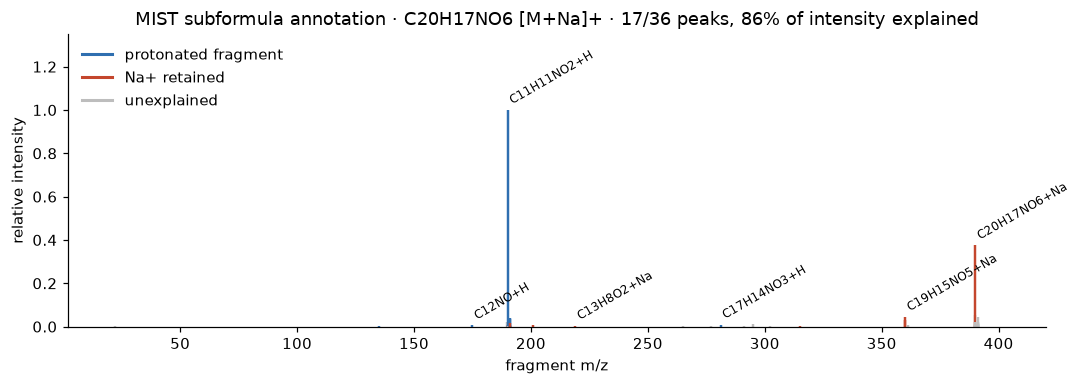

In [7]:
ex = pd.read_parquet(DATA / "example_spectra.parquet")
ex = ex[(ex.inchikey14 == "IYGYMKDQCDOMRE") & (ex.adduct == "[M+Na]+")].iloc[0]
emz, eint = np.asarray(ex.ms2_mzs), np.asarray(ex.ms2_normalized_intensities)
esub, eerr, etyp = annotate(emz, parse_adduct("[M+Na]+")[3], formula_vector(ex.molecular_formula))


def fstr(v):
    return "".join(f"{e}{'' if n == 1 else n}" for e, n in zip(ELEMS, v) if n)


fig, ax = plt.subplots(figsize=(10, 3.6))
cols = {0: "#bdbdbd", 1: "#2f6fb0", 2: "#c4462d", 3: "#6a3d9a"}
for m, i, t in zip(emz, eint, etyp):
    ax.vlines(m, 0, i, color=cols[int(t)], lw=1.6)
labelled = []
for k in np.argsort(-eint):
    if etyp[k] and all(abs(emz[k] - m) > 12 for m in labelled) and len(labelled) < 6:
        ion = "+H" if etyp[k] == 1 else "+Na"
        ax.annotate(f"{fstr(esub[k])}{ion}", (emz[k], eint[k]), xytext=(0, 4), textcoords="offset points",
                    ha="left", fontsize=8, rotation=30)
        labelled.append(emz[k])
ax.set_xlim(emz.min() - 20, ex.precursor_mz + 30)
ax.set(xlabel="fragment m/z", ylabel="relative intensity", ylim=(0, 1.35),
       title=f"MIST subformula annotation · {ex.molecular_formula} [M+Na]+ · "
             f"{(etyp > 0).sum()}/{len(etyp)} peaks, {eint[etyp > 0].sum() / eint.sum():.0%} of intensity explained")
ax.legend(handles=[plt.Line2D([], [], color=cols[c], lw=2, label=l) for c, l in
                   [(1, "protonated fragment"), (2, "Na+ retained"), (0, "unexplained")]], frameon=False, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "01_subformula_annotation.png", dpi=200); plt.show()

## 3. Candidate pools and training lists

* **Evaluation pool** of a spectrum: every catalog structure whose neutral mass is within 10 ppm of the neutral mass
  implied by the precursor m/z and adduct — exactly the team's mass filter. No shortlist.
* **Training list** of a spectrum: the true structure plus hard negatives — same-formula isomers first (only
  connectivity can separate them), then other formulas from the same mass window (at most 5), then nearest-mass
  structures if the window is small. Held-out structures are never used as negatives.

120,000 training spectra, mean list length 22.0 (13s)


Test candidate recall (true structure inside the 10 ppm pool): 94.91%


,count,mean,std,min,25%,50%,75%,90%,max
pool,8068.0,56.8,75.3,0.0,6.0,25.0,80.0,160.0,501.0
isomers,8068.0,31.4,58.2,0.0,2.0,8.0,30.0,95.0,477.0
formulas,8068.0,4.1,3.1,0.0,1.0,3.0,6.0,9.0,16.0


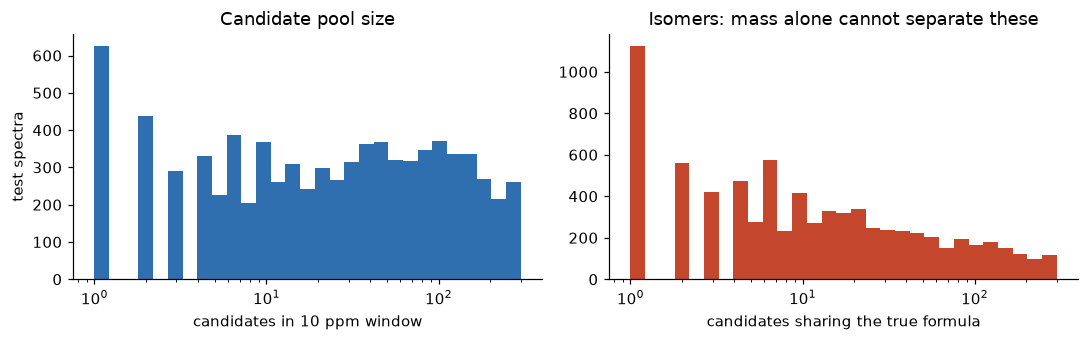

In [8]:
is_test_struct = np.array([ik in held_out for ik in G["ik14"]])
rng = np.random.default_rng(CFG["seed"])
by_fid = defaultdict(list)
for i, f in enumerate(cat_fid):
    if not is_test_struct[i]:
        by_fid[f].append(i)


def train_list(q):
    """True structure + negatives drawn like the test pool: isomers and other formulas inside the 10 ppm window;
    if the window is small, top up with the nearest-mass structures (a few extra formulas)."""
    true_i, nm = sample.at[q, "cat_idx"], sample.at[q, "neutral"]
    lo, hi = window(nm)
    pool = [i for i in range(lo, hi) if i != true_i and not is_test_struct[i]]
    iso = [i for i in pool if cat_fid[i] == TRUE_FID[q]]
    other = [i for i in pool if cat_fid[i] != TRUE_FID[q]]
    rng.shuffle(iso); rng.shuffle(other)
    keep_f = set(list(dict.fromkeys(cat_fid[i] for i in other))[:CFG["max_other_formulas"]])
    other = [i for i in other if cat_fid[i] in keep_f]
    negs = iso[:16] + other[:CFG["cand_cap"] - min(len(iso), 16)]
    if len(negs) < CFG["neg_per_query"]:
        lo2, hi2 = max(0, lo - 24), min(N_CAT, hi + 24)
        near = sorted((i for i in range(lo2, hi2) if not lo <= i < hi and not is_test_struct[i]), key=lambda i: abs(G["mass"][i] - nm))
        keep_f = list(dict.fromkeys(cat_fid[i] for i in near))[:CFG["max_neg_formulas"]]
        negs += [i for i in near if cat_fid[i] in keep_f][:CFG["neg_per_query"] - len(negs)]
    return [true_i] + negs


fit_q = np.where((sample.split2 == "train") & sample.neutral.notna())[0]
tune_q = np.where(sample.split2 == "tune")[0]
test_q = np.where(sample.split2 == "test_val")[0]
np_q = np.where(sample.split2 == "test_np")[0]
kaggle_q = np.where(sample.split2 == "kaggle")[0]
t0 = time.time()
TRAIN_LISTS = {q: train_list(q) for q in fit_q}
print(f"{len(fit_q):,} training spectra, mean list length {np.mean([len(v) for v in TRAIN_LISTS.values()]):.1f} "
      f"({time.time() - t0:.0f}s)")

pool_stats = []
for q in test_q:
    nm = sample.at[q, "neutral"]
    lo, hi = window(nm) if np.isfinite(nm) else (0, 0)
    pool_stats.append(dict(pool=hi - lo, isomers=int((cat_fid[lo:hi] == TRUE_FID[q]).sum()),
                           formulas=len(set(cat_fid[lo:hi])), covered=lo <= sample.at[q, "cat_idx"] < hi))
pool_stats = pd.DataFrame(pool_stats)
print(f"Test candidate recall (true structure inside the 10 ppm pool): {pool_stats.covered.mean():.2%}")
display(pool_stats[["pool", "isomers", "formulas"]].describe(percentiles=[.25, .5, .75, .9]).T.round(1))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(np.clip(pool_stats.pool, 1, 300), bins=np.logspace(0, np.log10(300), 30), color="#2f6fb0")
axes[0].set(xscale="log", xlabel="candidates in 10 ppm window", ylabel="test spectra", title="Candidate pool size")
axes[1].hist(np.clip(pool_stats.loc[pool_stats.covered, "isomers"], 1, 300), bins=np.logspace(0, np.log10(300), 30), color="#c4462d")
axes[1].set(xscale="log", xlabel="candidates sharing the true formula", title="Isomers: mass alone cannot separate these")
fig.tight_layout(); fig.savefig(FIG / "02_candidate_pools.png", dpi=200); plt.show()

### Precompute peak annotations for every (spectrum, candidate formula) pair
Grouping by formula means each subformula enumeration is computed once.

In [9]:
ANN_CACHE = {}


def build_pairs(pairs, cache=False):
    """pairs: list of (q, fid) -> dict index and stacked annotation arrays (grouped by formula for enumeration reuse)."""
    pairs = sorted(set(pairs), key=lambda x: (x[1], x[0]))
    idx = {p: i for i, p in enumerate(pairs)}
    SUB = np.zeros((len(pairs), P, N_EL), np.uint8); ERR = np.zeros((len(pairs), P), np.int8); TYP = np.zeros((len(pairs), P), np.int8)
    for i, (q, f) in enumerate(pairs):
        hit = ANN_CACHE.get((q, f))
        if hit is None:
            n = NPK[q]
            hit = annotate(MZ[q, :n].astype(float), SHIFTS[q], FVEC[f])
            if cache:
                ANN_CACHE[(q, f)] = hit
        n = len(hit[2])
        SUB[i, :n], ERR[i, :n], TYP[i, :n] = hit
    return idx, SUB, ERR, TYP


t0 = time.time()
log(f"annotating training pairs for {len(fit_q):,} spectra")
TRAIN_PAIRS = build_pairs([(q, cat_fid[i]) for q, lst in TRAIN_LISTS.items() for i in lst])
print(f"annotated {len(TRAIN_PAIRS[0]):,} (spectrum, formula) pairs in {time.time() - t0:.0f}s")
_, S_, _, T_ = TRAIN_PAIRS
true_pairs = np.array([TRAIN_PAIRS[0][(q, TRUE_FID[q])] for q in fit_q])
expl_true = np.array([(INT[q] * (T_[p] > 0)).sum() / max(INT[q].sum(), 1e-9) for q, p in zip(fit_q, true_pairs)])
print(f"With the true formula, annotation explains a median {np.median(expl_true):.0%} of spectral intensity.")

annotating training pairs for 120,000 spectra


annotated 540,985 (spectrum, formula) pairs in 144s


With the true formula, annotation explains a median 97% of spectral intensity.


## 4. Model

```
  spectrum + candidate formula ──► subformula tokens ──► MIST transformer (pairwise formula-difference bias) ──► z_spec ─┐
                                                                                        └─► 1,024-bit fingerprint (aux) │──► matching MLP ──► score
  candidate SMILES ──► RDKit graph ──► GINE message passing (4 layers) ──► mean ‖ max pool ──► z_graph ─────────────────┘
                                      + mass error, explained intensity, fingerprint log-likelihood
```

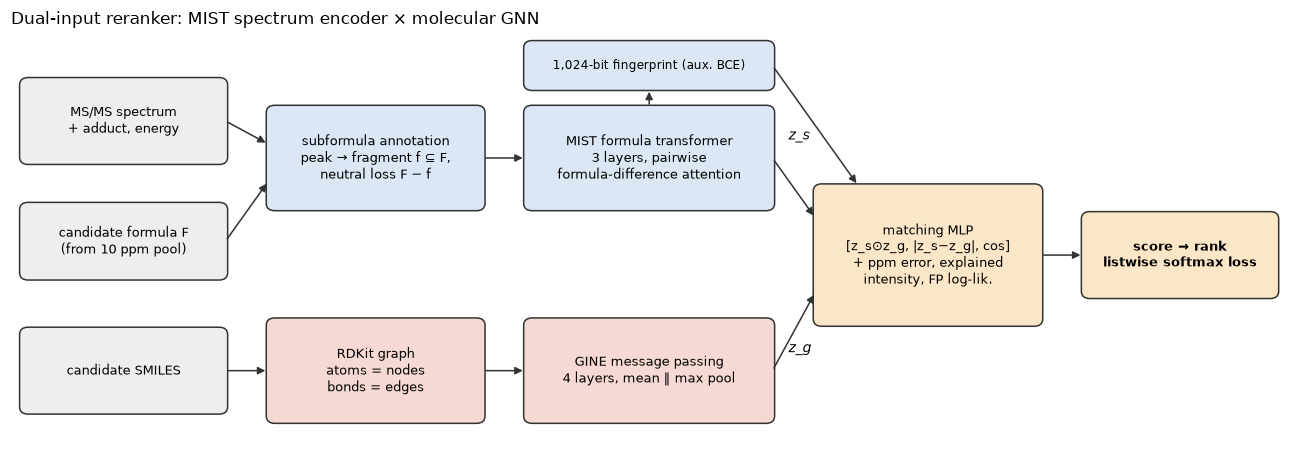

In [10]:
def box(ax, xy, w, h, text, fc, ec="#333333", fs=8.5, bold=False):
    ax.add_patch(plt.matplotlib.patches.FancyBboxPatch(xy, w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=fc, ec=ec, lw=1))
    ax.text(xy[0] + w / 2, xy[1] + h / 2, text, ha="center", va="center", fontsize=fs, weight="bold" if bold else "normal")


def arrow(ax, a, b):
    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="-|>", color="#333333", lw=1))


fig, ax = plt.subplots(figsize=(12, 4.2)); ax.set_xlim(0, 12); ax.set_ylim(0, 4.4); ax.axis("off")
blue, red, grey, gold = "#dbe7f4", "#f6d9d2", "#eeeeee", "#fbe6c8"
box(ax, (0.1, 3.0), 1.9, 0.9, "MS/MS spectrum\n+ adduct, energy", grey)
box(ax, (0.1, 1.75), 1.9, 0.8, "candidate formula F\n(from 10 ppm pool)", grey)
box(ax, (2.4, 2.5), 2.0, 1.1, "subformula annotation\npeak → fragment f ⊆ F,\nneutral loss F − f", blue)
box(ax, (4.8, 2.5), 2.3, 1.1, "MIST formula transformer\n3 layers, pairwise\nformula-difference attention", blue, bold=False)
box(ax, (4.8, 3.8), 2.3, 0.5, "1,024-bit fingerprint (aux. BCE)", blue, fs=8)
box(ax, (0.1, 0.3), 1.9, 0.9, "candidate SMILES", grey)
box(ax, (2.4, 0.2), 2.0, 1.1, "RDKit graph\natoms = nodes\nbonds = edges", red)
box(ax, (4.8, 0.2), 2.3, 1.1, "GINE message passing\n4 layers, mean ‖ max pool", red)
box(ax, (7.5, 1.25), 2.1, 1.5, "matching MLP\n[z_s⊙z_g, |z_s−z_g|, cos]\n+ ppm error, explained\nintensity, FP log-lik.", gold)
box(ax, (10.0, 1.55), 1.8, 0.9, "score → rank\nlistwise softmax loss", gold, bold=True)
for a, b in [((2.0, 3.45), (2.4, 3.2)), ((2.0, 2.15), (2.4, 2.8)), ((4.4, 3.05), (4.8, 3.05)), ((5.95, 3.6), (5.95, 3.8)),
             ((2.0, 0.75), (2.4, 0.75)), ((4.4, 0.75), (4.8, 0.75)), ((7.1, 3.05), (7.5, 2.4)), ((7.1, 0.75), (7.5, 1.6)),
             ((7.1, 4.05), (7.9, 2.75)), ((9.6, 2.0), (10.0, 2.0))]:
    arrow(ax, a, b)
ax.text(7.25, 3.25, "z_s", fontsize=9, style="italic"); ax.text(7.25, 0.95, "z_g", fontsize=9, style="italic")
ax.set_title("Dual-input reranker: MIST spectrum encoder × molecular GNN", fontsize=11, loc="left")
fig.tight_layout(); fig.savefig(FIG / "00_architecture.png", dpi=200); plt.show()

In [11]:
def fourier(x, n=16, lo=1.0, hi=2000.0):
    freqs = torch.exp(torch.linspace(math.log(2 * math.pi / hi), math.log(2 * math.pi / lo), n, device=x.device))
    a = x[..., None] * freqs
    return torch.cat([a.sin(), a.cos()], -1)


class PairBiasLayer(nn.Module):
    """Pre-norm transformer layer; attention logits get an additive bias from pairwise formula differences (MIST)."""

    def __init__(self, d, h, p):
        super().__init__()
        self.h, self.n1, self.n2 = h, nn.LayerNorm(d), nn.LayerNorm(d)
        self.qkv, self.o = nn.Linear(d, 3 * d), nn.Linear(d, d)
        self.ff = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Dropout(p), nn.Linear(4 * d, d))
        self.drop = nn.Dropout(p)

    def forward(self, x, bias):
        B, N, D = x.shape
        q, k, v = self.qkv(self.n1(x)).view(B, N, 3, self.h, D // self.h).permute(2, 0, 3, 1, 4)
        a = F.scaled_dot_product_attention(q, k, v, attn_mask=bias.to(q.dtype), dropout_p=0.0)
        x = x + self.drop(self.o(a.transpose(1, 2).reshape(B, N, D)))
        return x + self.drop(self.ff(self.n2(x)))


class MISTEncoder(nn.Module):
    """Formula-transformer spectrum encoder in the spirit of MIST (Goldman et al. 2023)."""

    def __init__(self, d, h, L, p, n_adducts, fp_bits):
        super().__init__()
        self.h, self.L = h, L
        tok_dim = 2 * N_EL + 32 + 3 + 5 + 1
        self.tok = nn.Sequential(nn.Linear(tok_dim, d), nn.GELU(), nn.Linear(d, d))
        self.meta = nn.Linear(META.shape[1], d)
        self.adduct = nn.Embedding(n_adducts, d)
        self.pair = nn.Sequential(nn.Linear(N_EL + 1, 64), nn.GELU(), nn.Linear(64, h * L))
        self.layers = nn.ModuleList(PairBiasLayer(d, h, p) for _ in range(L))
        self.norm = nn.LayerNorm(d)
        self.fp_head = nn.Sequential(nn.Linear(d, 2 * d), nn.GELU(), nn.Dropout(p), nn.Linear(2 * d, fp_bits))

    def forward(self, s):
        sub, mz, it, typ, err, npk, fvec = s["sub"], s["mz"], s["int"], s["typ"], s["err"], s["npk"], s["fvec"]
        B = sub.shape[0]
        # precursor token (full formula, no loss) + peak tokens (fragment formula, neutral loss F - f)
        sub_all = torch.cat([fvec[:, None], sub], 1)                                        # [B, N, 13]
        ann = torch.cat([torch.ones(B, 1, device=sub.device), (typ > 0).float()], 1)
        loss = (fvec[:, None] - sub_all).clamp(min=0) * ann[..., None]
        mz_all = torch.cat([s["prec"][:, None], mz], 1)
        typ_all = torch.cat([torch.full((B, 1), 4, device=sub.device, dtype=typ.dtype), typ], 1)
        feats = torch.cat([torch.log1p(sub_all) / 3, torch.log1p(loss) / 3, fourier(mz_all), torch.sqrt(torch.cat([torch.ones(B, 1, device=sub.device), it], 1))[..., None],
                           ann[..., None], torch.cat([torch.zeros(B, 1, device=sub.device), err / 20], 1)[..., None],
                           F.one_hot(typ_all.long(), 5).float(), (typ_all == 4).float()[..., None]], -1)
        x = self.tok(feats)
        ctx = (self.meta(s["meta"]) + self.adduct(s["adduct"])).to(x.dtype)
        x = torch.cat([x[:, :1] + ctx[:, None], x[:, 1:]], 1)                              # metadata enters via the precursor token
        N = x.shape[1]
        valid = torch.arange(N, device=x.device)[None] <= npk[:, None]                     # precursor + real peaks
        diff = sub_all[:, :, None] - sub_all[:, None, :]
        both = (ann[:, :, None] * ann[:, None, :])[..., None]
        pb = self.pair(torch.cat([torch.sign(diff) * torch.log1p(diff.abs()) * both, both], -1))  # [B,N,N,h*L]
        pb = pb.view(B, N, N, self.L, self.h).permute(3, 0, 4, 1, 2)
        mask = torch.zeros(B, 1, 1, N, device=x.device).masked_fill(~valid[:, None, None], float("-inf"))
        for l, layer in enumerate(self.layers):
            x = layer(x, pb[l] + mask)
        z = self.norm(x[:, 0])
        return z, self.fp_head(z)


class GINELayer(nn.Module):
    def __init__(self, d, p):
        super().__init__()
        self.bond = nn.ModuleList(nn.Embedding(v, d) for v in BOND_VOCAB)
        self.mlp = nn.Sequential(nn.Linear(d, 2 * d), nn.GELU(), nn.Linear(2 * d, d))
        self.eps, self.norm, self.drop = nn.Parameter(torch.zeros(1)), nn.LayerNorm(d), nn.Dropout(p)

    def forward(self, h, src, dst, battr):
        e = sum(emb(battr[:, i]) for i, emb in enumerate(self.bond))
        agg = torch.zeros_like(h).index_add_(0, dst, F.relu(h[src] + e))
        return self.norm(h + self.drop(self.mlp((1 + self.eps) * h + agg)))


class GraphEncoder(nn.Module):
    def __init__(self, d, L, p):
        super().__init__()
        self.atom = nn.ModuleList(nn.Embedding(v, d) for v in ATOM_VOCAB)
        self.layers = nn.ModuleList(GINELayer(d, p) for _ in range(L))
        self.out = nn.Sequential(nn.Linear(2 * d, d), nn.GELU(), nn.Linear(d, d), nn.LayerNorm(d))

    def forward(self, g):
        h = sum(emb(g["x"][:, i]) for i, emb in enumerate(self.atom))
        for layer in self.layers:
            h = layer(h, g["src"], g["dst"], g["battr"])
        n = g["n_graphs"]
        cnt = torch.zeros(n, device=h.device).index_add_(0, g["batch"], torch.ones_like(g["batch"], dtype=h.dtype)).clamp(min=1)
        mean = torch.zeros(n, h.shape[1], device=h.device, dtype=h.dtype).index_add_(0, g["batch"], h) / cnt[:, None]
        mx = torch.full((n, h.shape[1]), -1e4, device=h.device, dtype=h.dtype).scatter_reduce(
            0, g["batch"][:, None].expand_as(h), h, "amax", include_self=True)
        return self.out(torch.cat([mean, mx], 1))


class DualReranker(nn.Module):
    N_SCALARS = 4   # ppm error, explained intensity, annotated-peak fraction, fingerprint log-likelihood

    def __init__(self, use_graph=True, **kw):
        super().__init__()
        d = kw["d"]
        self.use_graph = use_graph
        self.spec = MISTEncoder(d, kw["heads"], kw["spec_layers"], kw["dropout"], len(ADDUCT_VOCAB), kw["fp_bits"])
        self.ps = nn.Linear(d, d)
        if use_graph:
            self.graph = GraphEncoder(d, kw["gnn_layers"], kw["dropout"])
            self.pg = nn.Linear(d, d)
            self.logit_scale = nn.Parameter(torch.tensor(math.log(10.0)))
        in_dim = (2 * d + 1 if use_graph else d) + self.N_SCALARS
        self.head = nn.Sequential(nn.Linear(in_dim, d), nn.GELU(), nn.Dropout(kw["dropout"]), nn.Linear(d, 1))
        self.mass_prior = nn.Parameter(torch.tensor([0.0, -2.0]))   # score += a*ppm + b*ppm^2 (Gaussian mass error)

    def encode_spectra(self, s, chunk=96):
        if self.training or s["sub"].shape[0] <= chunk:
            return self.spec(s)
        outs = [self.spec({k: v[i:i + chunk] for k, v in s.items()}) for i in range(0, s["sub"].shape[0], chunk)]
        return torch.cat([o[0] for o in outs]), torch.cat([o[1] for o in outs])

    def forward(self, s, seq_of_cand, cand_fp, scal, g=None, zg=None):
        zs, fp_logits = self.encode_spectra(s)
        l = fp_logits[seq_of_cand].float()
        fp_ll = (cand_fp * l - F.softplus(l)).mean(1, keepdim=True)          # log p(candidate fingerprint | spectrum, formula)
        a = self.ps(zs)[seq_of_cand]
        feats = [torch.cat([scal, fp_ll * 10], 1)]
        if self.use_graph:
            if zg is None:
                zg = self.graph(g)
            b = self.pg(zg)
            cos = F.cosine_similarity(a, b, dim=1)[:, None] * self.logit_scale.exp()
            feats = [a * b, (a - b).abs(), cos] + feats
        else:
            feats = [a] + feats
        ppm = scal[:, 0]
        prior = self.mass_prior[0] * ppm + self.mass_prior[1] * ppm ** 2
        return self.head(torch.cat(feats, 1)).squeeze(1) + prior, fp_logits, fp_ll.squeeze(1)

### Batching helpers (all graph gathering happens on the GPU)

In [12]:
T_ATOM = torch.from_numpy(G["atom_x"].astype(np.uint8)).to(DEVICE)   # compact on-GPU storage, cast after gather
T_BOND = torch.from_numpy(G["bond"].astype(np.int16)).to(DEVICE)
T_AN = torch.from_numpy(G["atom_n"].astype(np.int64)).to(DEVICE)
T_BN = torch.from_numpy(G["bond_n"].astype(np.int64)).to(DEVICE)
T_AOFF = torch.cumsum(T_AN, 0) - T_AN
T_BOFF = torch.cumsum(T_BN, 0) - T_BN
T_FP = torch.from_numpy(G["fp"]).to(DEVICE)
BITS = 2 ** torch.arange(7, -1, -1, device=DEVICE, dtype=torch.uint8)


def ranges(starts, counts):
    batch = torch.repeat_interleave(torch.arange(len(counts), device=DEVICE), counts)
    local = torch.arange(int(counts.sum()), device=DEVICE) - torch.repeat_interleave(torch.cumsum(counts, 0) - counts, counts)
    return batch, starts[batch] + local, local


def graph_batch(mol_ids):
    m = torch.as_tensor(mol_ids, device=DEVICE)
    na, nb = T_AN[m], T_BN[m]
    abatch, aidx, _ = ranges(T_AOFF[m], na)
    bbatch, bidx, _ = ranges(T_BOFF[m], nb)
    node_off = torch.cumsum(na, 0) - na
    b = T_BOND[bidx].long()
    return dict(x=T_ATOM[aidx].long(), batch=abatch, n_graphs=len(m), src=b[:, 0] + node_off[bbatch],
                dst=b[:, 1] + node_off[bbatch], battr=b[:, 2:])


def unpack_fp(mol_ids):
    return ((T_FP[torch.as_tensor(mol_ids, device=DEVICE)][..., None] & BITS) > 0).flatten(1).float()


def spec_batch(qs, fids, pair_arrays):
    idx, SUB, ERR, TYP = pair_arrays
    pid = np.array([idx[(q, f)] for q, f in zip(qs, fids)])
    qs = np.asarray(qs)
    t = lambda a, dt=torch.float32: torch.from_numpy(np.ascontiguousarray(a)).to(DEVICE, dt)
    return dict(sub=t(SUB[pid]), err=t(ERR[pid]), typ=t(TYP[pid], torch.long), mz=t(MZ[qs]), int=t(INT[qs]),
                npk=t(NPK[qs], torch.long), fvec=t(FVEC[fids]), prec=t(sample["precursor_mz"].values[qs]),
                meta=t(META[qs]), adduct=t(ADDUCT_ID[qs], torch.long))


def scalars(qs_c, cands, seq_typ, seq_int, seq_of_cand):
    nm = sample["neutral"].values[qs_c]
    ppm = np.abs(G["mass"][cands] - nm) / nm * 1e6 / CFG["ppm"]
    ann = (seq_typ > 0).float()
    expl = (seq_int * ann).sum(1) / seq_int.sum(1).clamp(min=1e-9)
    frac = ann.sum(1) / (seq_int > 0).float().sum(1).clamp(min=1)
    return torch.cat([torch.from_numpy(np.clip(ppm, 0, 3)).float().to(DEVICE)[:, None],
                      expl[seq_of_cand][:, None], frac[seq_of_cand][:, None]], 1)


def assemble(qs, cand_lists, pair_arrays):
    """Flatten (query, candidate list) into unique (query, formula) sequences + candidate rows."""
    seq_key, seq_of_cand, flat_q, flat_c = {}, [], [], []
    for q, cl in zip(qs, cand_lists):
        for c in cl:
            key = (q, cat_fid[c])
            if key not in seq_key:
                seq_key[key] = len(seq_key)
            seq_of_cand.append(seq_key[key]); flat_q.append(q); flat_c.append(c)
    keys = list(seq_key)
    s = spec_batch([k[0] for k in keys], np.array([k[1] for k in keys]), pair_arrays)
    soc = torch.tensor(seq_of_cand, device=DEVICE)
    scal = scalars(np.array(flat_q), np.array(flat_c), s["typ"], s["int"], soc)
    return s, soc, np.array(flat_c), scal, keys

## 5. Evaluation protocol (identical for every method)

Top-1, Top-5 and MRR@25 with **expected rank under ties** (Milton's convention: a structure tied with one competitor
for first place gets reciprocal rank 0.75). A spectrum whose true structure is not in the pool gets zero for every
method.

In [13]:
def tie_metrics(scores, true_pos):
    s_true = scores[true_pos]
    better = int((scores > s_true).sum()); ties = int((scores == s_true).sum())
    ranks = np.arange(better + 1, better + ties + 1)
    return dict(top1=float(np.mean(ranks <= 1)), top5=float(np.mean(ranks <= 5)),
                mrr25=float(np.mean(np.where(ranks <= 25, 1 / ranks, 0))), rank=float(ranks.mean()))


# DeepSets baseline: Milton's trained checkpoint, re-run on our pools (class + preprocessing copied from his recap)
class SpectrumDeepSets(nn.Module):
    def __init__(self, n_adducts, fp_bits=1024):
        super().__init__()
        self.n_adducts = n_adducts
        self.peak_encoder = nn.Sequential(nn.Linear(3, 64), nn.ReLU(), nn.Linear(64, 128), nn.ReLU())
        self.predictor = nn.Sequential(nn.Linear(256 + 5 + n_adducts, 256), nn.ReLU(), nn.Dropout(0.2), nn.Linear(256, fp_bits))

    def forward(self, peaks, mask, metadata, adducts):
        h = self.peak_encoder(peaks); valid = mask.unsqueeze(-1)
        mean = (h * valid).sum(1) / valid.sum(1).clamp(min=1)
        mx = h.masked_fill(~valid, -1e9).amax(1)
        mx = torch.where(mask.any(1, keepdim=True), mx, 0.0)
        ion = F.one_hot(adducts, num_classes=self.n_adducts).float()
        return self.predictor(torch.cat([mean, mx, metadata, ion], 1))


ds_ckpt = torch.load(DATA / "models" / "deepsets_fp_v1.pt", map_location="cpu", weights_only=True)
deepsets = SpectrumDeepSets(len(ds_ckpt["adduct_names"]), ds_ckpt["fp_bits"]).to(DEVICE).eval()
deepsets.load_state_dict(ds_ckpt["model_state"])
DS_ADDUCT = {a: i for i, a in enumerate(ds_ckpt["adduct_names"])}


@torch.no_grad()
def deepsets_probs(qs):
    out = []
    for q in qs:
        r = sample.iloc[q]
        mz, it = np.asarray(r.ms2_mzs, float), np.asarray(r.ms2_normalized_intensities, float)
        n = min(len(mz), len(it)); mz, it = mz[:n], it[:n]
        ok = np.isfinite(mz) & np.isfinite(it) & (mz > 0) & (it > 0); mz, it = mz[ok], it[ok]
        keep = np.argsort(it)[-128:]; mz, it = mz[keep], it[keep]
        pk = torch.tensor(np.column_stack([mz / 1000, np.sqrt(it), (r.precursor_mz - mz) / 1000]), dtype=torch.float32)[None]
        e = r.energy
        meta = torch.tensor([[r.precursor_mz / 1000, np.log1p(r.precursor_mz) / 8, 0 if np.isnan(e) else e / 80,
                              r.n_energies / 4, float(not np.isnan(e))]], dtype=torch.float32)
        ad = torch.tensor([DS_ADDUCT.get(r.adduct, 0)])
        out.append(torch.sigmoid(deepsets(pk.to(DEVICE), torch.ones(pk.shape[:2], dtype=torch.bool, device=DEVICE),
                                          meta.to(DEVICE), ad.to(DEVICE)))[0])
    return torch.stack(out)


@torch.no_grad()
def embed_catalog(model, bs=1024):
    model.eval()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()   # release cached training activations (4 GB laptop GPU)
    return torch.cat([model.graph(graph_batch(np.arange(i, min(i + bs, N_CAT)))) for i in range(0, N_CAT, bs)])


@torch.no_grad()
def score_pools(model, items, with_baselines=False, zg_all=None, chunk=24):
    """items: list of (q, candidate index array). Returns one {method: scores} dict per item."""
    model.eval()
    out = []
    for i in range(0, len(items), chunk):
        part = items[i:i + chunk]
        pa = build_pairs([(q, cat_fid[c]) for q, p in part for c in p], cache=True)
        s, soc, flat_c, scal, _ = assemble([q for q, _ in part], [p for _, p in part], pa)
        zg = zg_all[torch.as_tensor(flat_c, device=DEVICE)] if model.use_graph else None
        score, _, fp_ll = model(s, soc, unpack_fp(flat_c), scal, zg=zg)
        score, fp_ll = score.float().cpu().numpy(), fp_ll.float().cpu().numpy()
        if with_baselines:
            dsp = deepsets_probs([q for q, _ in part]).clamp(1e-6, 1 - 1e-6)
        off = 0
        for j, (q, p) in enumerate(part):
            n = len(p); d = {model.name: score[off:off + n]}
            if with_baselines:
                d["Mass only"] = -np.round(np.abs(G["mass"][p] - sample.at[q, "neutral"]), 6)
                d["MIST FP"] = fp_ll[off:off + n]
                y = unpack_fp(p); pr = dsp[j]
                d["DeepSets FP"] = (y * torch.log(pr) + (1 - y) * torch.log(1 - pr)).sum(1).cpu().numpy()
            out.append(d); off += n
    return out


def own_pool(q):
    nm = sample.at[q, "neutral"]
    lo, hi = window(nm) if np.isfinite(nm) else (0, 0)
    return np.arange(lo, hi)


@torch.no_grad()
def evaluate(model, qs, with_baselines=False):
    """Per-spectrum evaluation: each spectrum ranks its own 10 ppm pool."""
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    zg_all = embed_catalog(model) if model.use_graph else None
    rows, live = [], []
    for q in qs:
        p = own_pool(q)
        if len(p) and sample.at[q, "cat_idx"] in set(p):
            live.append((q, p))
        else:
            rows.append(dict(q=q, pool=len(p), covered=False))
    for (q, p), d in zip(live, score_pools(model, live, with_baselines, zg_all)):
        tpos = int(np.where(p == sample.at[q, "cat_idx"])[0][0])
        r = dict(q=q, pool=len(p), covered=True, isomers=int((cat_fid[p] == TRUE_FID[q]).sum()))
        for m, sc in d.items():
            r.update({f"{m}_{k}": v for k, v in tie_metrics(sc, tpos).items()})
        rows.append(r)
    return pd.DataFrame(rows).sort_values("q").reset_index(drop=True)


def molecule_pool(qs, fill=0):
    """10 ppm pool around the median neutral mass of a molecule's spectra (optionally padded with nearest masses)."""
    nm = np.nanmedian(sample["neutral"].values[qs])
    lo, hi = window(nm)
    if hi - lo < fill:
        near = np.argsort(np.abs(G["mass"][max(0, lo - fill):hi + fill] - nm))[:fill] + max(0, lo - fill)
        return np.unique(np.concatenate([np.arange(lo, hi), near]))
    return np.arange(lo, hi)


def aggregate(score_list):
    """Combine a molecule's spectra: mean of per-spectrum log-softmax over the shared candidate pool."""
    ls = [sc - np.logaddexp.reduce(sc) for sc in score_list]
    return np.round(np.mean(ls, 0), 9)


@torch.no_grad()
def evaluate_molecules(model, qs, with_baselines=False):
    """Per-molecule evaluation (Kaggle protocol): all spectra of a molecule rank one shared pool.
    Reports the aggregated ranking ('multi') and the average single-spectrum ranking ('single')."""
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    zg_all = embed_catalog(model) if model.use_graph else None
    groups = pd.Series(qs).groupby(sample["molecule"].values[qs]).apply(list)
    rows = []
    for mol, mq in groups.items():
        p = molecule_pool(mq); true_i = sample.at[mq[0], "cat_idx"]
        r = dict(molecule=mol, n_spectra=len(mq), pool=len(p), covered=bool(len(p)) and true_i in set(p))
        if r["covered"]:
            tpos = int(np.where(p == true_i)[0][0])
            r["isomers"] = int((cat_fid[p] == TRUE_FID[mq[0]]).sum())
            scored = score_pools(model, [(q, p) for q in mq], with_baselines, zg_all)
            for m in scored[0]:
                r.update({f"{m}_{k}": v for k, v in tie_metrics(aggregate([d[m] for d in scored]), tpos).items()})
                single = pd.DataFrame([tie_metrics(d[m], tpos) for d in scored]).mean()
                r.update({f"{m}_single_{k}": v for k, v in single.items()})
        rows.append(r)
    return pd.DataFrame(rows)


def summarize(df, methods):
    out = {}
    for m in methods:
        out[m] = {k: df[f"{m}_{k}"].fillna(0).mean() for k in ["top1", "top5", "mrr25"]}
    return pd.DataFrame(out).T

## 6. Training

Listwise softmax cross-entropy over (true structure + 15 sampled hard negatives) per spectrum, plus MIST's fingerprint
loss (BCE on the true-formula encoding). AdamW, cosine schedule with warm-up, mixed precision on GPU, model selection on
the tune split (structure-disjoint from both train and test).

In [14]:
FP_TRUE = None


def train(use_graph, name, epochs=CFG["epochs"]):
    torch.manual_seed(CFG["seed"]); np.random.seed(CFG["seed"])
    model = DualReranker(use_graph=use_graph, **CFG).to(DEVICE)
    model.name = name
    n_params = sum(p.numel() for p in model.parameters())
    slug = name.replace(" ", "_")
    ck, hf = CKPT / f"{slug}.pt", RES / f"training_history_{slug}{'_quick' if QUICK else ''}.csv"
    if not RETRAIN and ck.exists() and hf.exists():
        model.load_state_dict(torch.load(ck, weights_only=True, map_location=DEVICE))
        h = pd.read_csv(hf)
        model.train_minutes, model.peak_mem, model.n_params = h.minutes.iloc[-1], h.peak_mem_gib.iloc[-1], n_params
        print(f"[{name}] loaded checkpoint + history (set RETRAIN=1 to train again)")
        return model, h
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    steps = epochs * math.ceil(len(fit_q) / CFG["batch_queries"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG["lr"], total_steps=steps, pct_start=0.05)
    scaler = torch.amp.GradScaler(enabled=DEVICE.type == "cuda")
    hist, best, t_start = [], -1, time.time()
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    n_steps = math.ceil(len(fit_q) / CFG["batch_queries"])
    for ep in range(epochs):
        model.train(); perm = np.random.permutation(fit_q); tot = dict(rank=0.0, fp=0.0, n=0)
        for b in range(0, len(perm), CFG["batch_queries"]):
            if (b // CFG["batch_queries"]) % 500 == 0:
                log(f"[{name}] epoch {ep + 1}/{epochs} step {b // CFG['batch_queries']}/{n_steps} "
                    f"({(time.time() - t_start) / 60:.1f} min)")
            qs = perm[b:b + CFG["batch_queries"]]
            lists = []
            for q in qs:
                lst = TRAIN_LISTS[q]
                negs = lst[1:]
                if len(negs) > CFG["neg_per_query"]:
                    negs = list(np.random.choice(negs, CFG["neg_per_query"], replace=False))
                lists.append([lst[0]] + negs)
            s, soc, flat_c, scal, keys = assemble(qs, lists, TRAIN_PAIRS)
            g = graph_batch(flat_c) if use_graph else None
            with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
                score, fp_logits, _ = model(s, soc, unpack_fp(flat_c), scal, g=g)
            score = score.float()
            # listwise loss: softmax over each query's list, true structure first
            lens = torch.tensor([len(l) for l in lists], device=DEVICE)
            qid = torch.repeat_interleave(torch.arange(len(lists), device=DEVICE), lens)
            mx = torch.full((len(lists),), -1e9, device=DEVICE).scatter_reduce(0, qid, score, "amax")
            lse = torch.zeros(len(lists), device=DEVICE).index_add_(0, qid, (score - mx[qid]).exp()).log() + mx
            first = torch.cumsum(lens, 0) - lens
            rank_loss = (lse - score[first]).mean()
            true_seq = torch.tensor([keys.index((q, TRUE_FID[q])) for q in qs], device=DEVICE)
            fp_loss = F.binary_cross_entropy_with_logits(fp_logits[true_seq].float(), unpack_fp([l[0] for l in lists]))
            loss = rank_loss + CFG["fp_weight"] * fp_loss
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            tot["rank"] += rank_loss.item() * len(qs); tot["fp"] += fp_loss.item() * len(qs); tot["n"] += len(qs)
        tune = summarize(evaluate(model, tune_q), [name]).loc[name]
        hist.append(dict(epoch=ep + 1, rank_loss=tot["rank"] / tot["n"], fp_bce=tot["fp"] / tot["n"], **{f"tune_{k}": v for k, v in tune.items()},
                         minutes=(time.time() - t_start) / 60))
        log(f"[{name}] epoch {ep + 1}/{epochs}  rank {hist[-1]['rank_loss']:.3f}  fp {hist[-1]['fp_bce']:.4f}  "
              f"tune MRR@25 {tune['mrr25']:.4f}  top1 {tune['top1']:.4f}  ({hist[-1]['minutes']:.1f} min)")
        if tune["mrr25"] > best:
            best = tune["mrr25"]; torch.save(model.state_dict(), ck)
    model.load_state_dict(torch.load(ck, weights_only=True))
    model.train_minutes = (time.time() - t_start) / 60
    model.peak_mem = torch.cuda.max_memory_allocated() / 2**30 if DEVICE.type == "cuda" else float("nan")
    model.n_params = n_params
    hist = pd.DataFrame(hist).assign(peak_mem_gib=model.peak_mem)
    hist.to_csv(hf, index=False)
    return model, hist


dual, hist_dual = train(True, "Dual MIST+GNN")
nograph, hist_nog = train(False, "Dual (no GNN)")

[Dual MIST+GNN] loaded checkpoint + history (set RETRAIN=1 to train again)
[Dual (no GNN)] loaded checkpoint + history (set RETRAIN=1 to train again)


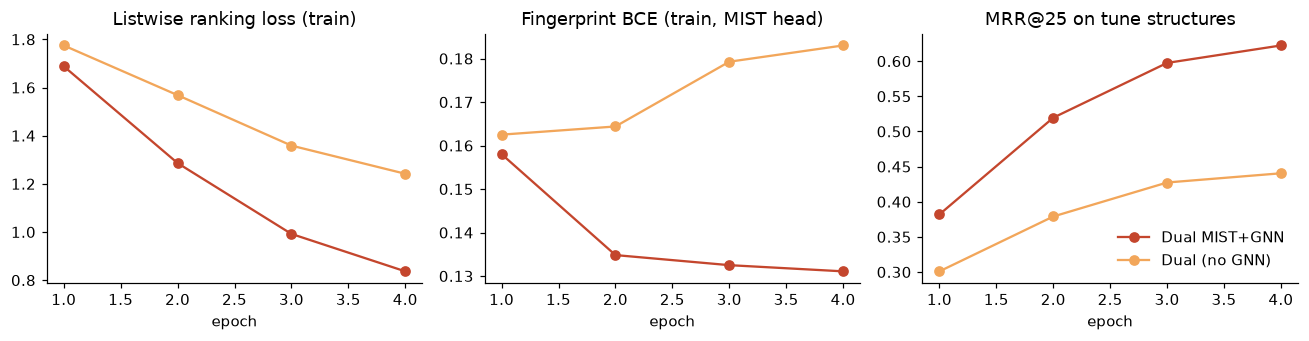

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for h, name in [(hist_dual, "Dual MIST+GNN"), (hist_nog, "Dual (no GNN)")]:
    axes[0].plot(h.epoch, h.rank_loss, "o-", color=COLORS[name], label=name)
    axes[1].plot(h.epoch, h.fp_bce, "o-", color=COLORS[name], label=name)
    axes[2].plot(h.epoch, h.tune_mrr25, "o-", color=COLORS[name], label=name)
axes[0].set(title="Listwise ranking loss (train)", xlabel="epoch")
axes[1].set(title="Fingerprint BCE (train, MIST head)", xlabel="epoch")
axes[2].set(title="MRR@25 on tune structures", xlabel="epoch"); axes[2].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "03_training_curves.png", dpi=200); plt.show()

## 7. Results I — Milton's validation benchmark (per spectrum, full 275k catalog)

In [16]:
log("evaluating Milton's validation spectra")
t0 = time.time()
res = evaluate(dual, test_q, with_baselines=True)
infer_ms = (time.time() - t0) / len(test_q) * 1000
res = res.merge(evaluate(nograph, test_q)[["q"] + [f"Dual (no GNN)_{k}" for k in ["top1", "top5", "mrr25", "rank"]]],
                on="q", how="left")
res["inchikey14"] = sample["inchikey14"].values[res.q]
res["adduct"] = sample["adduct"].values[res.q]
res["ingest_lib"] = sample["ingest_lib"].values[res.q]
METHODS = ["Mass only", "DeepSets FP", "MIST FP", "Dual (no GNN)", "Dual MIST+GNN"]
table = summarize(res, METHODS)
table["candidate recall"] = res.covered.mean()
res.to_csv(RES / "per_query_test_results.csv", index=False)
table.round(4).to_csv(RES / "summary_test.csv")
print(f"Catalog: {CATALOG_NAME}; {len(res):,} test spectra; {res.inchikey14.nunique():,} structures")
print("Milton's recap on the same spectra and catalog: Mass only 0.3360, DeepSets likelihood 0.2663 MRR@25")
display(table.round(4))

evaluating Milton's validation spectra


Catalog: CASMI26 train.parquet structures (275,810); 8,068 test spectra; 4,930 structures
Milton's recap on the same spectra and catalog: Mass only 0.3360, DeepSets likelihood 0.2663 MRR@25


,top1,top5,mrr25,candidate recall
Mass only,0.2179,0.4922,0.3436,0.9491
DeepSets FP,0.1613,0.4096,0.2758,0.9491
MIST FP,0.1741,0.4649,0.3045,0.9491
Dual (no GNN),0.3148,0.6510,0.4632,0.9491
Dual MIST+GNN,0.4150,0.7527,0.5595,0.9491


,delta,lo,hi
Dual MIST+GNN − Mass only,0.2160,0.2049,0.2279
Dual MIST+GNN − MIST FP,0.2550,0.2409,0.2690
Dual MIST+GNN − Dual (no GNN),0.0964,0.0862,0.1070
MIST FP − DeepSets FP,0.0287,0.0222,0.0357


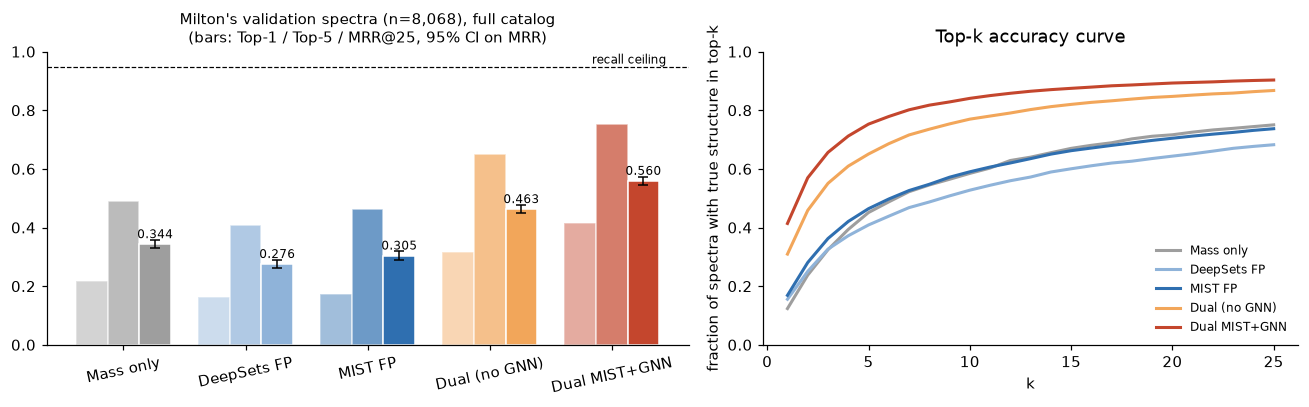

In [17]:
def bootstrap(df, methods, key, pairs, B=1000):
    """95% CIs by resampling whole structures/molecules (spectra of one molecule are not independent)."""
    groups = df.groupby(key).indices; keys = list(groups)
    vals = {m: df[f"{m}_mrr25"].fillna(0).values for m in methods}
    boot = {m: [] for m in methods}; rs = np.random.default_rng(0)
    for _ in range(B):
        idx = np.concatenate([groups[keys[k]] for k in rs.integers(0, len(keys), len(keys))])
        for m in methods:
            boot[m].append(vals[m][idx].mean())
    ci = {m: np.percentile(boot[m], [2.5, 97.5]) for m in methods}
    out = {}
    for a, b_ in pairs:
        d = np.array(boot[a]) - np.array(boot[b_])
        out[f"{a} − {b_}"] = dict(delta=vals[a].mean() - vals[b_].mean(), lo=np.percentile(d, 2.5), hi=np.percentile(d, 97.5))
    return ci, pd.DataFrame(out).T


PAIRS = [("Dual MIST+GNN", "Mass only"), ("Dual MIST+GNN", "MIST FP"), ("Dual MIST+GNN", "Dual (no GNN)"), ("MIST FP", "DeepSets FP")]
ci, paired = bootstrap(res, METHODS, "inchikey14", PAIRS)
display(paired.round(4))
paired.round(4).to_csv(RES / "paired_differences_mrr25.csv")


def results_figure(table, ci, ranks, recall, title, path, unit="spectra"):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[1.2, 1]))
    x = np.arange(len(METHODS)); w = 0.26
    for k, met in enumerate(["top1", "top5", "mrr25"]):
        axes[0].bar(x + (k - 1) * w, table.loc[METHODS, met], w, color=[COLORS[m] for m in METHODS],
                    alpha=[0.45, 0.7, 1.0][k], edgecolor="white")
    m_ = table.loc[METHODS, "mrr25"].values
    axes[0].errorbar(x + w, m_, yerr=np.array([[m_[i] - ci[m][0], ci[m][1] - m_[i]] for i, m in enumerate(METHODS)]).T,
                     fmt="none", ecolor="black", capsize=3, lw=1)
    for i, v in enumerate(m_):
        axes[0].text(i + w, v + 0.02, f"{v:.3f}", ha="center", fontsize=8)
    axes[0].set_xticks(x, METHODS, rotation=12); axes[0].set_ylim(0, 1)
    axes[0].set_title(f"{title}\n(bars: Top-1 / Top-5 / MRR@25, 95% CI on MRR)", fontsize=10)
    axes[0].axhline(recall, ls="--", color="black", lw=0.8)
    axes[0].text(4.45, recall + 0.01, "recall ceiling", ha="right", fontsize=8)
    ks = np.arange(1, 26)
    for m in METHODS:
        axes[1].plot(ks, [(ranks[m] <= k).mean() for k in ks], color=COLORS[m], lw=2, label=m)
    axes[1].set(xlabel="k", ylabel=f"fraction of {unit} with true structure in top-k", title="Top-k accuracy curve", ylim=(0, 1))
    axes[1].legend(frameon=False, fontsize=8)
    fig.tight_layout(); fig.savefig(path, dpi=200); plt.show()


ranks = {m: res[f"{m}_rank"].where(res.covered, np.inf).fillna(np.inf).values for m in METHODS}
results_figure(table, ci, ranks, res.covered.mean(), f"Milton's validation spectra (n={len(res):,}), full catalog",
               FIG / "04_main_results.png")

### Where does the graph help? Breakdown by isomer ambiguity and source library

,Mass only,DeepSets FP,MIST FP,Dual (no GNN),Dual MIST+GNN,spectra
isomer bucket,,,,,,
1 (unique formula),0.921,0.664,0.696,0.967,0.970,1125
2–3,0.634,0.483,0.515,0.709,0.764,984
4–10,0.373,0.304,0.332,0.508,0.593,1974
11–30,0.176,0.195,0.213,0.356,0.490,1582
31–100,0.065,0.064,0.110,0.229,0.398,1249
>100,0.021,0.021,0.051,0.133,0.309,743


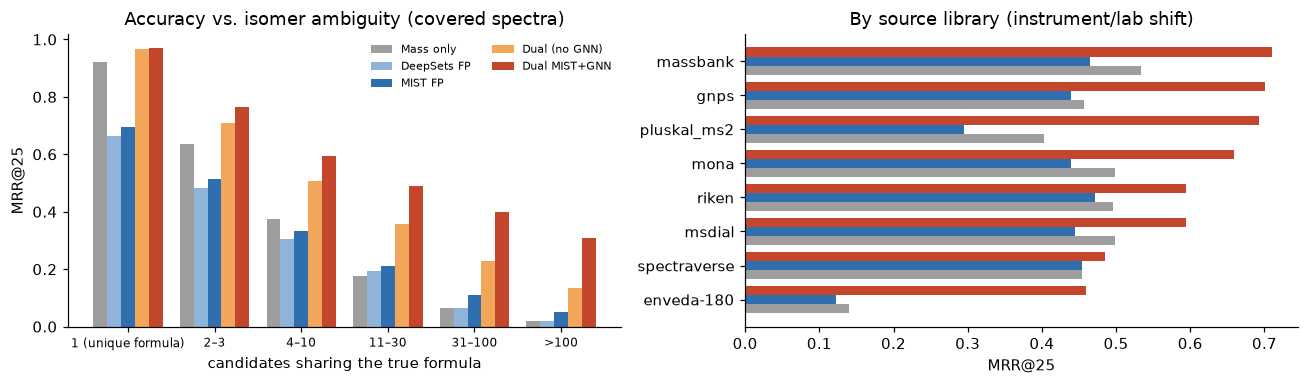

In [18]:
cov = res[res.covered].copy()
cov["isomer bucket"] = pd.cut(cov.isomers, [0, 1, 3, 10, 30, 100, 100_000],
                              labels=["1 (unique formula)", "2–3", "4–10", "11–30", "31–100", ">100"])
by_iso = cov.groupby("isomer bucket", observed=True)[[f"{m}_mrr25" for m in METHODS]].mean()
by_iso.columns = METHODS
by_iso["spectra"] = cov.groupby("isomer bucket", observed=True).size()
display(by_iso.round(3))
by_lib = cov.groupby("ingest_lib")[[f"{m}_mrr25" for m in ["Mass only", "MIST FP", "Dual MIST+GNN"]]].mean()
by_lib.columns = ["Mass only", "MIST FP", "Dual MIST+GNN"]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
xb = np.arange(len(by_iso)); w = 0.16
for k, m in enumerate(METHODS):
    axes[0].bar(xb + (k - 2) * w, by_iso[m], w, color=COLORS[m], label=m)
axes[0].set_xticks(xb, by_iso.index, fontsize=8); axes[0].set(xlabel="candidates sharing the true formula", ylabel="MRR@25",
                                                                title="Accuracy vs. isomer ambiguity (covered spectra)")
axes[0].legend(frameon=False, fontsize=7, ncol=2)
by_lib = by_lib.sort_values("Dual MIST+GNN")
yl = np.arange(len(by_lib))
for k, m in enumerate(by_lib.columns):
    axes[1].barh(yl + (k - 1) * 0.27, by_lib[m], 0.27, color=COLORS[m], label=m)
axes[1].set_yticks(yl, by_lib.index); axes[1].set(xlabel="MRR@25", title="By source library (instrument/lab shift)")
fig.tight_layout(); fig.savefig(FIG / "05_breakdown.png", dpi=200); plt.show()

## 8. Results II — natural products on the test instrument (`enveda-np-examples`, per molecule)

Closest available proxy for the hidden Kaggle test set: 250 natural products measured on the same timsTOF and
pipeline, 1–16 spectra per molecule, all structures held out of training. Each molecule ranks **one** pool (10 ppm
around the median neutral mass of its spectra). We compare two protocols:

* **single**: the average score when only one spectrum is used;
* **multi**: all of the molecule's spectra combined by averaging per-spectrum log-softmax scores.

This answers the proposal's central question: does combining spectra measured at several energies or adducts help?

evaluating enveda-np-examples molecules


250 molecules, 1,184 spectra (median 4 per molecule); candidate recall 100.0%; median pool 13
0 of these structures were in the DeepSets checkpoint's training sample.


single spectrum               all spectra (aggregated)         \
                         top1   top5  mrr25                     top1   top5   
Mass only               0.209  0.601  0.380                    0.221  0.608   
DeepSets FP             0.162  0.494  0.315                    0.164  0.486   
MIST FP                 0.181  0.543  0.344                    0.184  0.536   
Dual (no GNN)           0.325  0.762  0.508                    0.328  0.804   
Dual MIST+GNN           0.416  0.819  0.590                    0.452  0.864   

                      
               mrr25  
Mass only      0.392  
DeepSets FP    0.314  
MIST FP        0.345  
Dual (no GNN)  0.522  
Dual MIST+GNN  0.627

,delta,lo,hi
Dual MIST+GNN − Mass only,0.2345,0.1905,0.2773
Dual MIST+GNN − MIST FP,0.2818,0.2302,0.3305
Dual MIST+GNN − Dual (no GNN),0.1041,0.0614,0.1460
Dual MIST+GNN − Dual MIST+GNN_single,0.0364,0.0185,0.0543


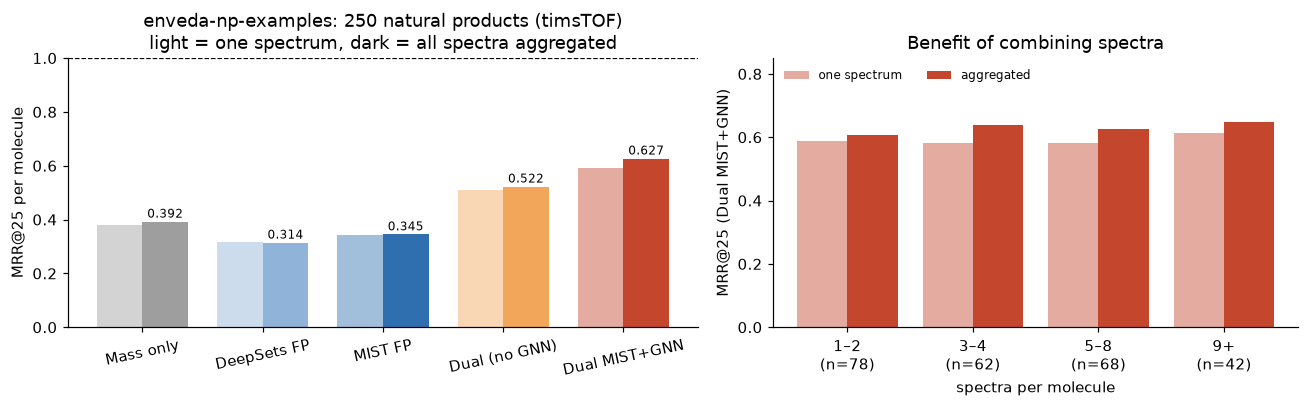

In [19]:
log("evaluating enveda-np-examples molecules")
np_d = evaluate_molecules(dual, np_q, with_baselines=True)
np_n = evaluate_molecules(nograph, np_q)
np_res = np_d.merge(np_n[["molecule"] + [c for c in np_n.columns if c.startswith("Dual (no GNN)")]], on="molecule")
np_res.to_csv(RES / "per_molecule_np_examples.csv", index=False)
multi = summarize(np_res, METHODS)
single = summarize(np_res, [f"{m}_single" for m in METHODS]); single.index = METHODS
np_table = pd.concat({"single spectrum": single, "all spectra (aggregated)": multi}, axis=1)
np_table.round(4).to_csv(RES / "summary_np_examples.csv")
milton_train_ik = set(milton.loc[milton.split == "train", "inchikey14"])
print(f"{len(np_res)} molecules, {np_res.n_spectra.sum():,} spectra (median {np_res.n_spectra.median():.0f} per molecule); "
      f"candidate recall {np_res.covered.mean():.1%}; median pool {np_res.pool.median():.0f}")
print(f"{len(np_ik & milton_train_ik)} of these structures were in the DeepSets checkpoint's training sample.")
display(np_table.round(3))
np_ci, np_paired = bootstrap(np_res, METHODS + ["Dual MIST+GNN_single"], "molecule",
                             PAIRS[:3] + [("Dual MIST+GNN", "Dual MIST+GNN_single")])   # last row: aggregation gain
display(np_paired.round(4))
np_paired.round(4).to_csv(RES / "paired_differences_np_examples.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[1.2, 1]))
x = np.arange(len(METHODS)); w = 0.38
axes[0].bar(x - w / 2, single["mrr25"], w, color=[COLORS[m] for m in METHODS], alpha=0.45, label="one spectrum")
axes[0].bar(x + w / 2, multi["mrr25"], w, color=[COLORS[m] for m in METHODS], label="all spectra aggregated")
for i, (a_, b_) in enumerate(zip(single["mrr25"], multi["mrr25"])):
    axes[0].text(i + w / 2, b_ + 0.015, f"{b_:.3f}", ha="center", fontsize=8)
axes[0].axhline(np_res.covered.mean(), ls="--", color="black", lw=0.8)
axes[0].set_xticks(x, METHODS, rotation=12); axes[0].set_ylim(0, 1)
axes[0].set(ylabel="MRR@25 per molecule", title=f"enveda-np-examples: {len(np_res)} natural products (timsTOF)\n"
                                                 "light = one spectrum, dark = all spectra aggregated")
mm = np_res[np_res.covered]
nb = pd.cut(mm.n_spectra, [0, 2, 4, 8, 100], labels=["1–2", "3–4", "5–8", "9+"])
gain = mm.groupby(nb, observed=True)[["Dual MIST+GNN_single_mrr25", "Dual MIST+GNN_mrr25"]].mean()
gx = np.arange(len(gain))
axes[1].bar(gx - 0.2, gain.iloc[:, 0], 0.4, color=COLORS["Dual MIST+GNN"], alpha=0.45, label="one spectrum")
axes[1].bar(gx + 0.2, gain.iloc[:, 1], 0.4, color=COLORS["Dual MIST+GNN"], label="aggregated")
axes[1].set_xticks(gx, [f"{i}\n(n={c})" for i, c in zip(gain.index, mm.groupby(nb, observed=True).size())])
axes[1].set(xlabel="spectra per molecule", ylabel="MRR@25 (Dual MIST+GNN)", title="Benefit of combining spectra")
axes[1].set_ylim(0, 0.85); axes[1].legend(frameon=False, fontsize=8, ncol=2, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "07_np_examples_multispectrum.png", dpi=200); plt.show()

### Qualitative example: a spectrum where mass alone is ambiguous

Query VVCAGJCSXGLCDW  [M-H]-  pool=15  isomers=8; mass-only expected rank 4.5, dual rank 1


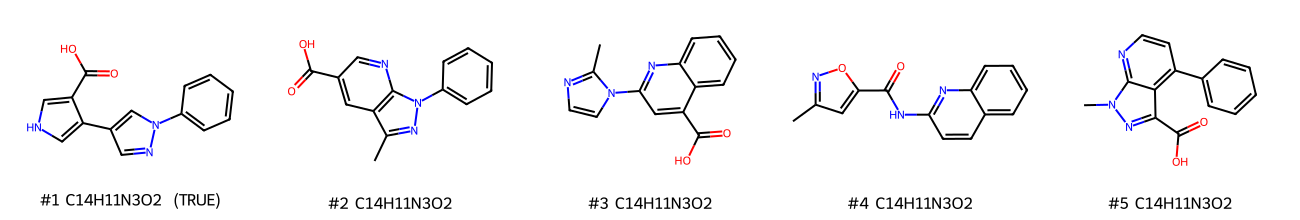

In [20]:
@torch.no_grad()
def ranked_pool(q, model):
    p = own_pool(q)
    pa = build_pairs([(q, cat_fid[c]) for c in p])
    s, soc, flat_c, scal, _ = assemble([q], [p], pa)
    score, _, _ = model(s, soc, unpack_fp(flat_c), scal, g=graph_batch(flat_c))
    return p[np.argsort(-score.float().cpu().numpy())]


cand = res[(res["Dual MIST+GNN_top1"] == 1) & (res["Mass only_top1"] < 0.2) & (res.isomers.between(4, 12))]
if len(cand):
    q = int(cand.sample(1, random_state=1).q.iloc[0])
    top = ranked_pool(q, dual)[:5]
    true_i = sample.at[q, "cat_idx"]
    mols = [Chem.MolFromSmiles(G["smiles"][i]) for i in top]
    legends = [f"#{r + 1} {G['formula'][i]}" + ("  (TRUE)" if i == true_i else "") for r, i in enumerate(top)]
    rq = res.set_index("q")
    print(f"Query {sample.at[q, 'inchikey14']}  {sample.at[q, 'adduct']}  pool={rq.at[q, 'pool']}  "
          f"isomers={int(rq.at[q, 'isomers'])}; mass-only expected rank {rq.at[q, 'Mass only_rank']:.1f}, dual rank 1")
    img = Draw.MolsToGridImage(mols, molsPerRow=5, subImgSize=(260, 220), legends=legends)
    img.save(FIG / "06_example_ranking.png") if hasattr(img, "save") else None
    display(img)

## 9. Cost (proposal: report time and memory alongside accuracy)

In [21]:
cost = pd.DataFrame({
    "parameters": [dual.n_params, nograph.n_params, sum(p.numel() for p in deepsets.parameters())],
    "train minutes": [dual.train_minutes, nograph.train_minutes, np.nan],
    "peak GPU GiB (train)": [dual.peak_mem, nograph.peak_mem, np.nan],
}, index=["Dual MIST+GNN", "Dual (no GNN)", "DeepSets FP (Milton)"])
cost.loc["Dual MIST+GNN", "test ms / spectrum (all methods, incl. annotation)"] = infer_ms
display(cost.round(2))
cost.round(3).to_csv(RES / "cost.csv")

,parameters,train minutes,peak GPU GiB (train),"test ms / spectrum (all methods, incl. annotation)"
Dual MIST+GNN,4650976,36.61,1.36,8.78
Dual (no GNN),3249627,20.19,1.13,NaN
DeepSets FP (Milton),354432,NaN,NaN,NaN


## 10. Kaggle-format submission from `test.parquet`

One ranked list of up to 25 SMILES per `molecule_id`, built from the aggregated dual-encoder scores over the catalog
pool. Kaggle replaces the visible `test.parquet` (training examples) with the hidden set when it re-runs a notebook.
Two limits apply:

* retrieval can only find Kaggle class 1–2 molecules that are in the catalog — class 3 (novel) needs de novo
  generation;
* an actual submission must run inside a Kaggle notebook with internet access off.

In [22]:
zg_all = embed_catalog(dual)
groups = pd.Series(kaggle_q).groupby(sample["molecule"].values[kaggle_q]).apply(list)
rows = []
for mol, mq in groups.items():
    p = molecule_pool(mq, fill=25)
    sc = aggregate([d[dual.name] for d in score_pools(dual, [(q, p) for q in mq], zg_all=zg_all)])
    top = p[np.argsort(-sc, kind="stable")[:25]]
    rows.append(dict(molecule_id=mol, smiles=";".join(G["smiles"][top])))
sub = pd.DataFrame(rows)
ref = pd.read_csv(KAGGLE / "sample_submission.csv") if (KAGGLE / "sample_submission.csv").exists() else None
if ref is not None:                      # same molecules, same order as Kaggle's sample_submission.csv
    assert set(ref.molecule_id) == set(sub.molecule_id)
    sub = sub.set_index("molecule_id").loc[ref.molecule_id].reset_index()
assert sub.molecule_id.is_unique and set(sub.molecule_id) == set(sample.loc[kaggle_q, "molecule"])
assert sub.smiles.str.split(";").map(len).max() <= 25 and sub.smiles.notna().all()
sub.to_csv(RES / "submission.csv", index=False)
print(f"submission.csv: {len(sub)} molecules, {sub.smiles.str.split(';').map(len).mean():.1f} guesses on average")
display(sub.head(3))

submission.csv: 400 molecules, 25.0 guesses on average


,molecule_id,smiles
0,m_005e53,O=C(O)c1cccnc1CN1CCC(c2ccccc2Br)CC1;CN(Cc1nccc...
1,m_006153,COc1ccc(N2CC(C(=O)Nc3nncn3C3CC3)CC2=O)cc1;Cc1c...
2,m_00b5aa,COc1ccccc1NC(=O)CNC1CC(C)(C)OC1(C)C;COC(=O)c1n...


## 11. Take-aways for the report

Run: seed 42; 120,000 training spectra (one per structure, 62% of the structures also measured outside enveda-180);
4 epochs; full catalog of 275,810 structures; 95% CIs from 1,000 bootstrap resamples of whole structures/molecules.

**Milton's validation benchmark** (8,068 spectra, 4,930 held-out structures, full catalog, candidate recall 94.9%)

| Method | Top-1 | Top-5 | MRR@25 |
|---|---:|---:|---:|
| Mass only | 0.218 | 0.492 | 0.344 |
| DeepSets FP (Milton's checkpoint) | 0.161 | 0.410 | 0.276 |
| MIST FP (fingerprint head only) | 0.174 | 0.465 | 0.305 |
| Dual, no GNN (ablation) | 0.315 | 0.651 | 0.463 |
| **Dual MIST + GNN** | **0.415** | **0.753** | **0.560** |

**Natural products on the test instrument** (`enveda-np-examples`: 250 molecules / 1,184 timsTOF spectra, per
molecule, all spectra aggregated)

| Method | MRR@25, one spectrum | MRR@25, aggregated | Top-1, aggregated |
|---|---:|---:|---:|
| Mass only | 0.380 | 0.392 | 0.221 |
| DeepSets FP | 0.315 | 0.314 | 0.164 |
| MIST FP | 0.344 | 0.345 | 0.184 |
| Dual, no GNN | 0.508 | 0.522 | 0.328 |
| **Dual MIST + GNN** | **0.590** | **0.627** | **0.452** |

* **Pipeline sanity check.** Our mass-only and DeepSets baselines (0.344 / 0.276) reproduce Milton's full-catalog
  numbers (0.336 / 0.266). The small gaps come from the generic adduct parser covering more adducts.
* **The dual model roughly doubles Top-1 over mass alone.**
  - Milton's benchmark: +0.216 MRR@25 [0.205, 0.228].
  - Natural products: +0.235 [0.191, 0.277].
  - It is the first team model to beat mass-only ranking on the full catalog.
* **The GNN carries the isomer problem.** With the spectrum encoder and all other inputs fixed, the graph branch adds
  +0.096 [0.086, 0.107] on Milton's benchmark and +0.104 [0.061, 0.146] on the natural products. The gain grows with
  ambiguity: for more than 100 same-formula candidates, MRR@25 goes from 0.13 without the GNN to 0.31 with it, versus
  0.02 for mass alone.
* **MIST encodes spectra better than DeepSets** (+0.029 [0.022, 0.036] as a fingerprint retriever). On its own,
  though, fingerprint retrieval still loses to mass. The value comes from combining formula-annotated spectra,
  molecular graphs and mass error in one learned scorer.
* **Multiple spectra help (the proposal's central question).** Averaging per-spectrum log-softmax scores over a
  molecule's spectra adds +0.036 [0.019, 0.054] MRR@25 for the dual model. The gain is largest for molecules with
  3+ spectra.
* **Cost.** The model has 4.7M parameters. Training takes 37 min at 1.4 GiB peak GPU memory on a 4 GB RTX 3050 Ti,
  and scoring takes about 10 ms per spectrum (full catalog, all baselines included).

  Windows note: the NVIDIA driver silently spills CUDA memory into system RAM, which made the first full run about 8×
  slower. Capping the process memory fraction fixed it.
* **Limitations.**
  - Retrieval cannot find Kaggle's class-3 (novel) structures; that needs the team's de novo generator.
  - Candidate recall caps MRR@25 at 0.95.
  - One seed only, and 120k of the 270k available training structures (compute budget).
  - Tune MRR was still rising at epoch 4.
  - `enveda-180` (synthetic, timsTOF) is still the hardest library.
  - A real Kaggle submission must run as an offline Kaggle notebook. Section 10 only demonstrates the output format.

**References.** Goldman et al., *MIST*, Nat. Mach. Intell. 5, 965 (2023) · Kalia et al., *JESTR*, Bioinformatics
btaf354 (2025) · Bushuiev et al., *MassSpecGym*, NeurIPS D&B (2024) · Dührkop et al., *CSI:FingerID*, PNAS (2015) ·
Xu et al., *GIN*, ICLR (2019) · Hu et al., *Strategies for pre-training GNNs* (GINE), ICLR (2020) · Zaheer et al.,
*Deep Sets*, NeurIPS (2017) · Gilmer et al., *MPNN*, ICML (2017).